In [37]:
%pip install pandas numpy seaborn matplotlib
import pandas as pd

# Import the protein abundance dataset
protein_data = pd.read_csv('dataset-protein-totalareas.csv')

# Import the metadata for sample replicates
metadata = pd.read_csv('MetaData-Replicates.csv')

print("Protein data shape:", protein_data.shape)
print("Metadata shape:", metadata.shape)

Note: you may need to restart the kernel to use updated packages.
Protein data shape: (9528, 51)
Metadata shape: (48, 7)



[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: C:\Users\macco\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Unnormalized data and corresponding box plot

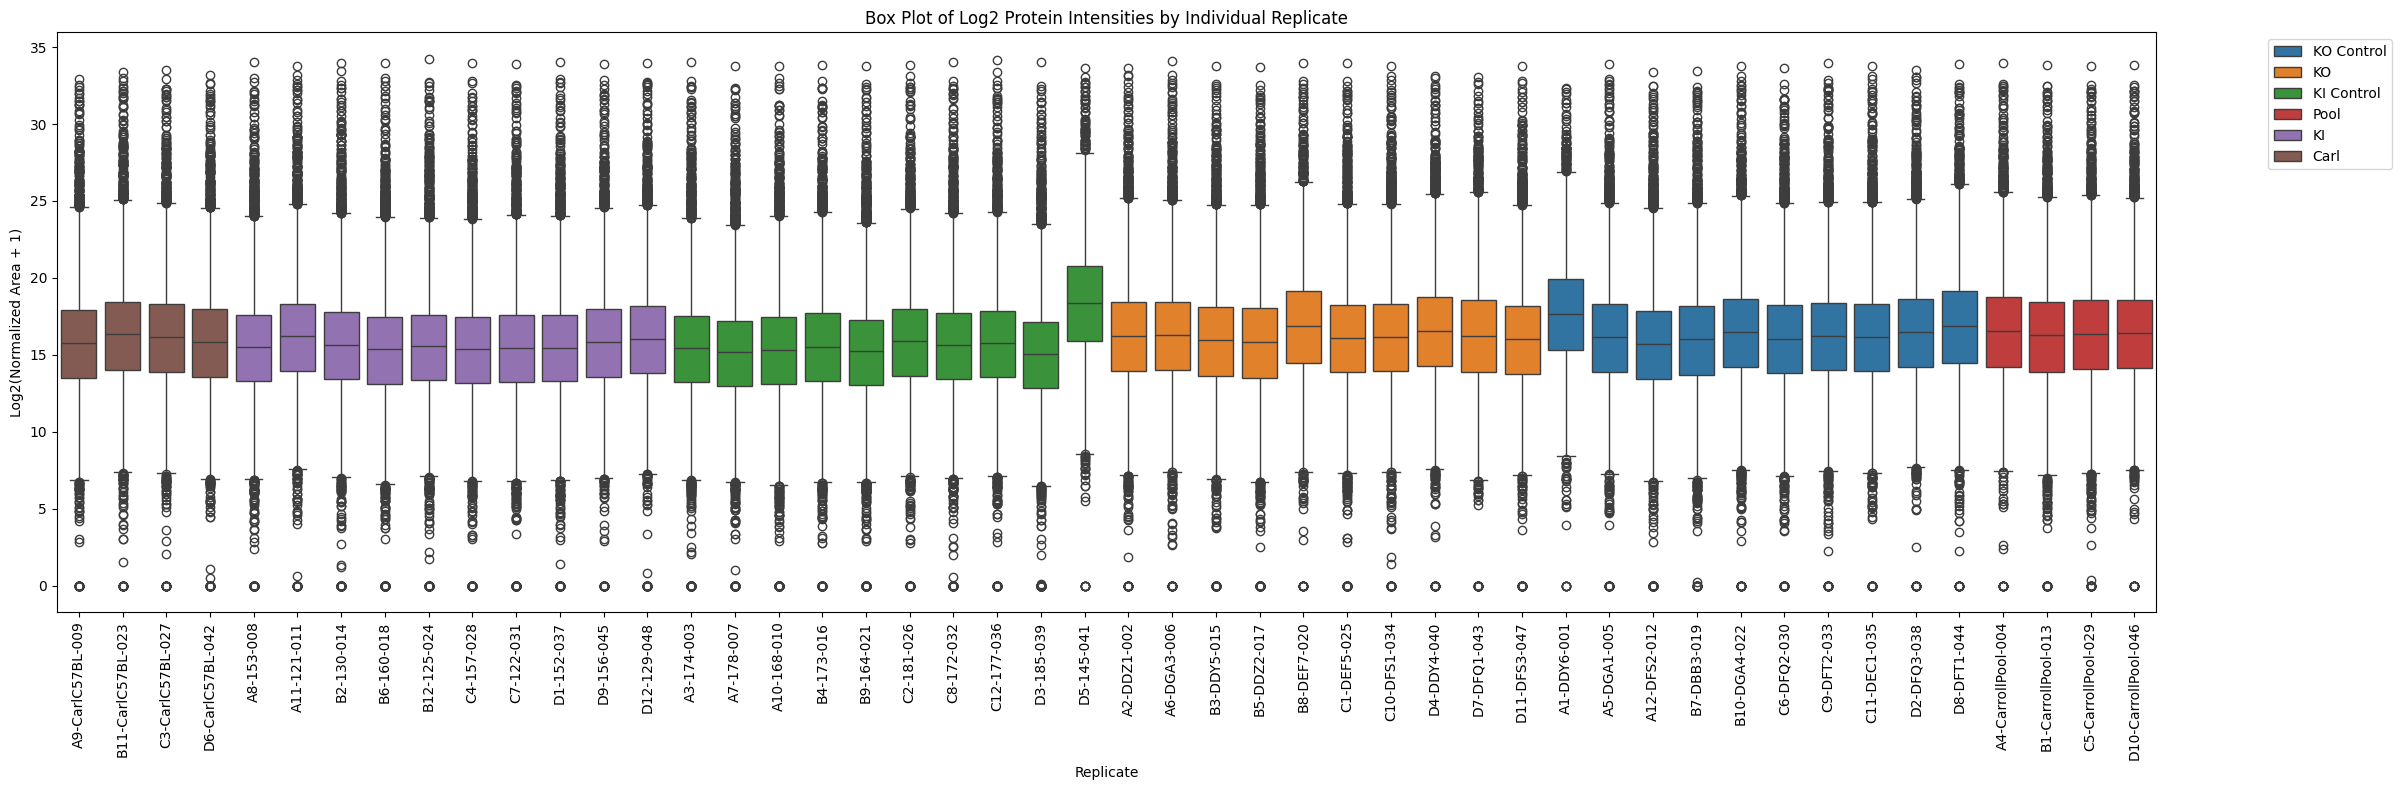

In [38]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get the sample columns (excluding the first 3 columns which are protein info)
sample_columns = protein_data.columns[3:]

# Create a long format dataframe for plotting
plot_data = []

for col in sample_columns:
    # Extract replicate name from column name (remove ' Sum Normalized Area')
    replicate = col.replace(' Sum Normalized Area', '')
    
    # Find the corresponding group from metadata
    group = metadata[metadata['Replicate'] == replicate]['Group'].iloc[0] if len(metadata[metadata['Replicate'] == replicate]) > 0 else 'Unknown'
    
    # Extract sample number (last 3 digits)
    sample_number = int(replicate[-3:]) if replicate[-3:].isdigit() else 0
    
    # Get log2 values (add small constant to avoid log(0))
    log2_values = np.log2(protein_data[col] + 1)
    
    # Add to plot data
    for value in log2_values:
        plot_data.append({
            'Replicate': replicate, 
            'Group': group, 
            'Sample_Number': sample_number,
            'Log2_Intensity': value
        })

# Convert to dataframe
plot_df = pd.DataFrame(plot_data)

# Create ordered list of replicates (by group first, then by sample number)
replicate_order = plot_df.groupby(['Group', 'Sample_Number', 'Replicate']).size().reset_index()
replicate_order = replicate_order.sort_values(['Group', 'Sample_Number'])['Replicate'].tolist()

# Create the box plot with individual replicates
plt.figure(figsize=(24, 8))
ax = sns.boxplot(data=plot_df, x='Replicate', y='Log2_Intensity', hue='Group', order=replicate_order)

# Rotate x-axis labels for better readability
plt.xticks(rotation=90)
plt.title('Box Plot of Log2 Protein Intensities by Individual Replicate')
plt.ylabel('Log2(Normalized Area + 1)')
plt.xlabel('Replicate')

# Move legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

Read metadata and look at the available groups.

In [39]:
# First, let's examine the metadata to see what groups are available
print("Available groups in metadata:")
print(metadata['Group'].value_counts())
print("\nSample metadata:")
print(metadata.head(10))

# Check if 'Pool' and 'Carl' groups exist
pool_samples = metadata[metadata['Group'] == 'Pool']
carl_samples = metadata[metadata['Group'] == 'Carl']

print(f"\nPool samples: {len(pool_samples)}")
print(pool_samples[['Replicate', 'Group']])

print(f"\nCarl samples: {len(carl_samples)}")
print(carl_samples[['Replicate', 'Group']])

Available groups in metadata:
Group
KO Control    10
KO            10
KI Control    10
KI            10
Pool           4
Carl           4
Name: count, dtype: int64

Sample metadata:
            Replicate Sample Type  Analyte Concentration       Group  \
0         A1-DDY6-001     Unknown                    NaN  KO Control   
1         A2-DDZ1-002     Unknown                    NaN          KO   
2          A3-174-003     Unknown                    NaN  KI Control   
3  A4-CarrollPool-004     Unknown                    NaN        Pool   
4         A5-DGA1-005     Unknown                    NaN  KO Control   
5         A6-DGA3-006     Unknown                    NaN          KO   
6          A7-178-007     Unknown                    NaN  KI Control   
7          A8-153-008     Unknown                    NaN          KI   
8    A9-CarlC57BL-009     Unknown                    NaN        Carl   
9         A10-168-010     Unknown                    NaN  KI Control   

       Genotype   Age  Se

Make Correlation plots of the unnormalized data


[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: C:\Users\macco\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Creating correlation matrix for Pool with 4 samples
Samples: ['A4-CarrollPool-004', 'B1-CarrollPool-013', 'C5-CarrollPool-029', 'D10-CarrollPool-046']


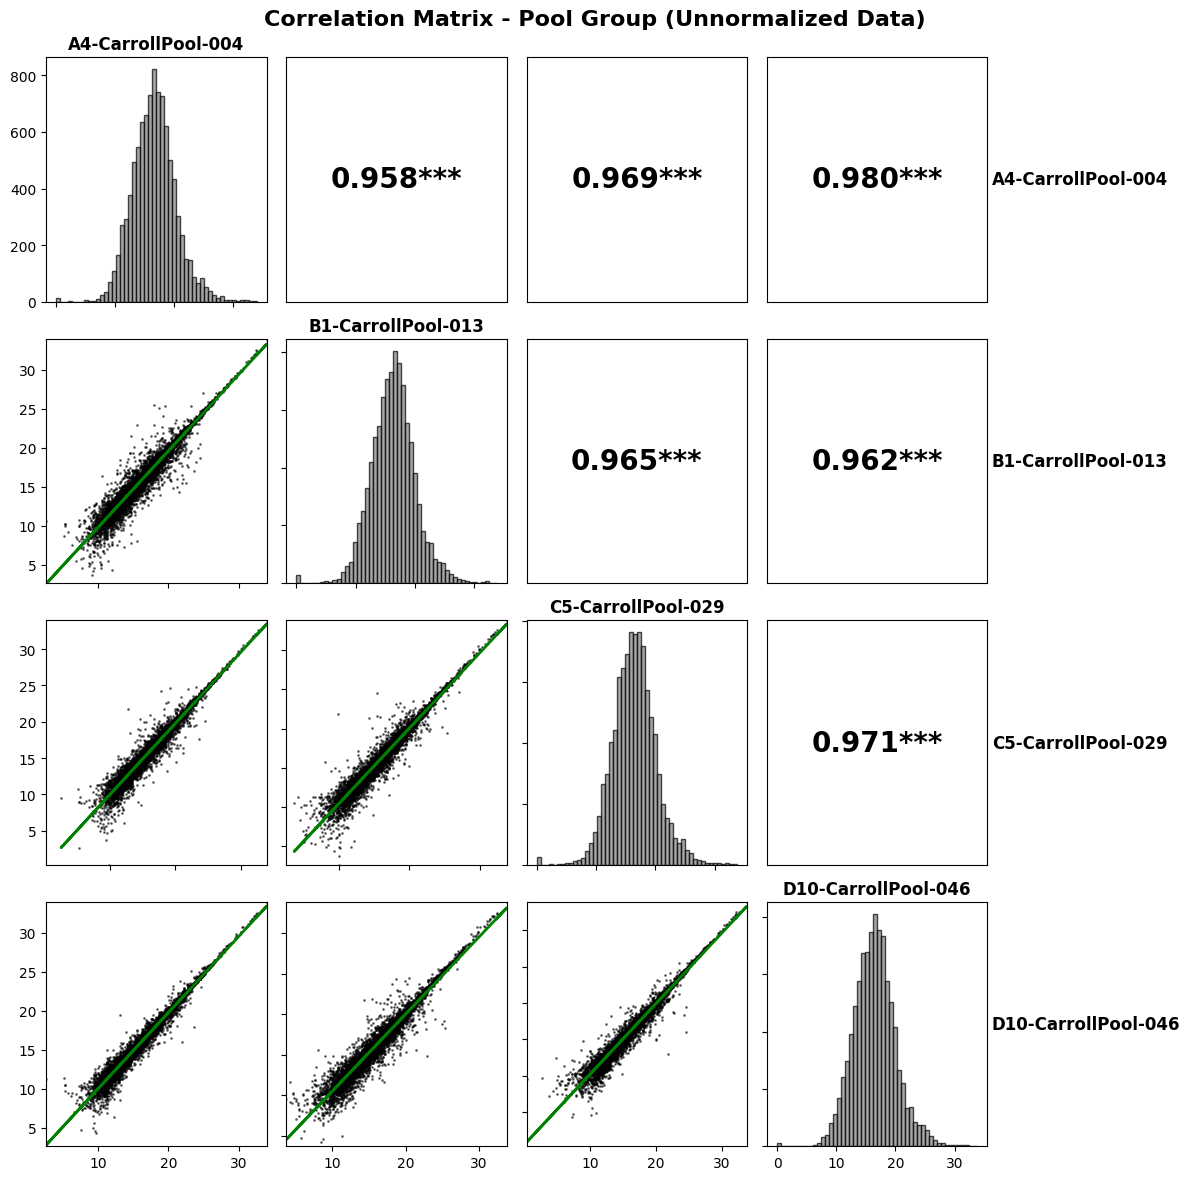

Creating correlation matrix for Carl with 4 samples
Samples: ['A9-CarlC57BL-009', 'B11-CarlC57BL-023', 'C3-CarlC57BL-027', 'D6-CarlC57BL-042']


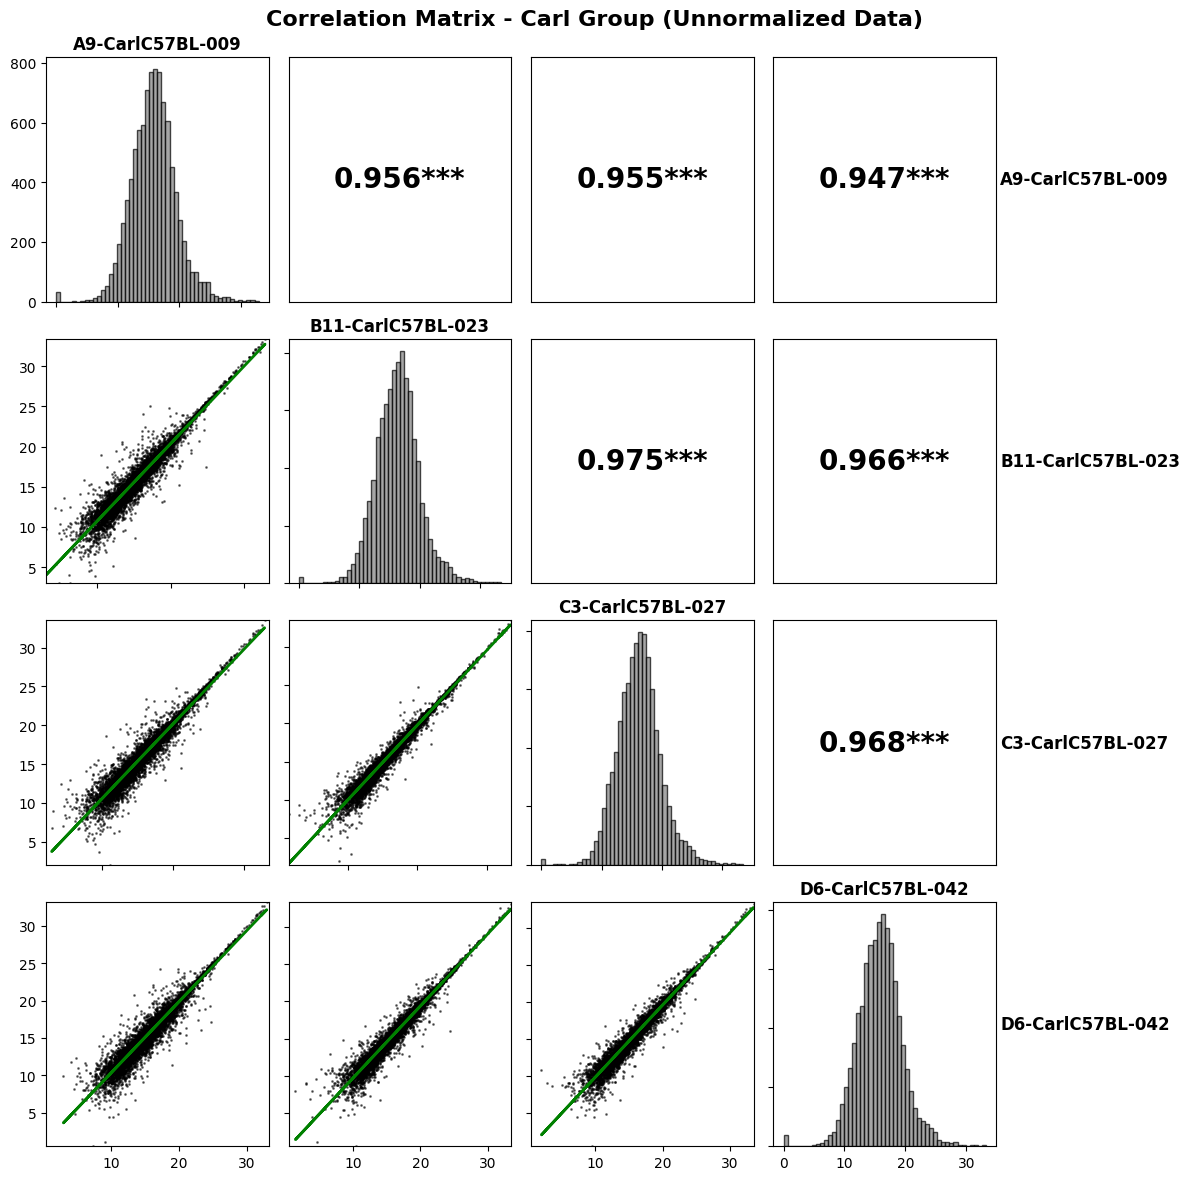

In [40]:
%pip install scipy
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr

def create_correlation_matrix_plot(data, group_name, samples_df):
    """
    Create a correlation matrix plot similar to the attached image
    """
    # Get sample columns (all columns except the first 3 metadata columns)
    sample_cols = data.columns[3:]  # Skip Protein, Protein Description, Protein Gene
    
    # Get column names for the specified group
    group_replicates = samples_df['Replicate'].tolist()
    group_cols = [col for col in sample_cols if any(rep in col for rep in group_replicates)]
    
    if len(group_cols) < 2:
        print(f"Not enough samples found for {group_name} group")
        return
    
    print(f"Creating correlation matrix for {group_name} with {len(group_cols)} samples")
    print(f"Samples: {[col.replace(' Sum Normalized Area', '') for col in group_cols]}")
    
    # Extract data for these samples (use original unnormalized data)
    subset_data = data[group_cols].copy()
    
    # Remove rows with all NaN values
    subset_data = subset_data.dropna(how='all')
    
    # Fill remaining NaN values with 0 (or use another strategy)
    subset_data = subset_data.fillna(0)
    
    # Apply log2 transformation with pseudocount
    log2_data = np.log2(subset_data + 1)
    
    # Create short names for samples
    short_names = [col.replace(' Sum Normalized Area', '').replace('EV-', '') for col in group_cols]
    log2_data.columns = short_names
    
    # Calculate correlation matrix
    corr_matrix = log2_data.corr()
    
    # Create the figure
    n_samples = len(group_cols)
    fig, axes = plt.subplots(n_samples, n_samples, figsize=(3*n_samples, 3*n_samples))
    
    if n_samples == 1:
        axes = np.array([[axes]])
    elif n_samples == 2:
        axes = axes.reshape(2, 2)
    
    for i in range(n_samples):
        for j in range(n_samples):
            ax = axes[i, j]
            
            if i == j:
                # Diagonal: histogram
                ax.hist(log2_data.iloc[:, i], bins=50, color='gray', alpha=0.7, edgecolor='black')
                ax.set_title(short_names[i], fontsize=12, fontweight='bold')
                ax.set_xlabel('')
                ax.set_ylabel('')
                
            elif i > j:
                # Lower triangle: scatter plot
                x_data = log2_data.iloc[:, j]
                y_data = log2_data.iloc[:, i]
                
                # Remove pairs where either value is 0 (after log transformation would be -inf)
                valid_mask = (x_data > 0) & (y_data > 0)
                x_clean = x_data[valid_mask]
                y_clean = y_data[valid_mask]
                
                ax.scatter(x_clean, y_clean, alpha=0.5, s=1, color='black')
                
                # Add regression line
                if len(x_clean) > 10:  # Only if we have enough points
                    z = np.polyfit(x_clean, y_clean, 1)
                    p = np.poly1d(z)
                    ax.plot(x_clean, p(x_clean), "g-", linewidth=2)
                
                # Set axis limits to be the same
                all_values = np.concatenate([x_clean, y_clean])
                if len(all_values) > 0:
                    min_val, max_val = all_values.min(), all_values.max()
                    ax.set_xlim(min_val, max_val)
                    ax.set_ylim(min_val, max_val)
                
                ax.set_xlabel('')
                ax.set_ylabel('')
                
            else:
                # Upper triangle: correlation coefficient
                corr_val = corr_matrix.iloc[i, j]
                ax.text(0.5, 0.5, f'{corr_val:.3f}***', 
                       horizontalalignment='center', verticalalignment='center',
                       fontsize=20, fontweight='bold', transform=ax.transAxes)
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 1)
                ax.set_xticks([])
                ax.set_yticks([])
            
            # Remove tick labels for cleaner look
            if i < n_samples - 1:
                ax.set_xticklabels([])
            if j > 0:
                ax.set_yticklabels([])
    
    # Add sample names on the right side
    for i in range(n_samples):
        ax_right = axes[i, -1]
        ax_right.text(1.02, 0.5, short_names[i], rotation=0, 
                     verticalalignment='center', transform=ax_right.transAxes,
                     fontsize=12, fontweight='bold')
    
    plt.suptitle(f'Correlation Matrix - {group_name} Group (Unnormalized Data)', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return corr_matrix

# Create correlation matrix for Pool group
if len(pool_samples) > 0:
    pool_corr = create_correlation_matrix_plot(protein_data, "Pool", pool_samples)
else:
    print("No Pool samples found")

# Create correlation matrix for Carl group  
if len(carl_samples) > 0:
    carl_corr = create_correlation_matrix_plot(protein_data, "Carl", carl_samples)
else:
    print("No Carl samples found")

Perform median centering.  Median centering looks like it is doing a horrible job here.

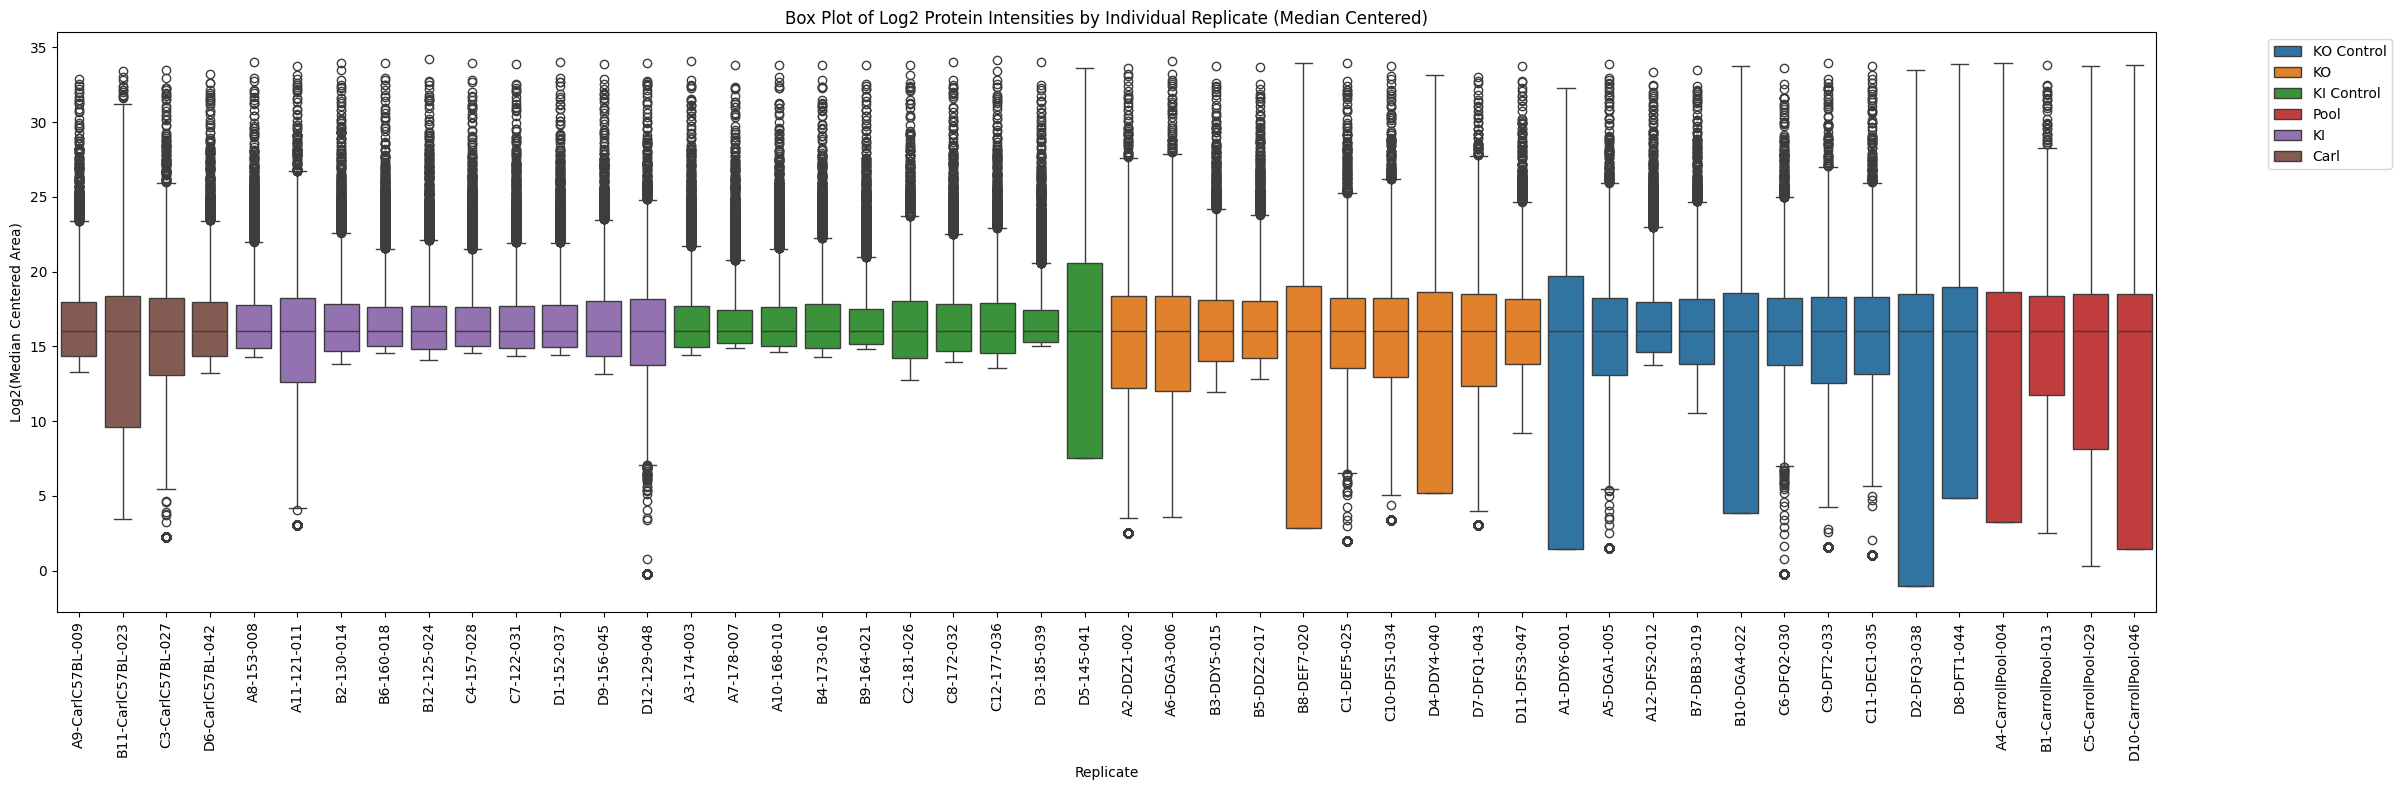

In [41]:
# Perform median centering on the protein data
centered_protein_data = protein_data.copy()

# Calculate the overall median across all replicate medians
overall_median = np.median([np.median(protein_data[col]) for col in sample_columns])

# Calculate median for each replicate and center
replicate_medians = {}
for col in sample_columns:
    replicate_medians[col] = np.median(protein_data[col])

# Apply median centering: add (overall_median - replicate_median) to each value
for col in sample_columns:
    centering_offset = overall_median - replicate_medians[col]
    centered_protein_data[col] = protein_data[col] + centering_offset

# Create centered plot data
centered_plot_data = []

for col in sample_columns:
    # Extract replicate name from column name
    replicate = col.replace(' Sum Normalized Area', '')
    
    # Find the corresponding group from metadata
    group = metadata[metadata['Replicate'] == replicate]['Group'].iloc[0] if len(metadata[metadata['Replicate'] == replicate]) > 0 else 'Unknown'
    
    # Extract sample number
    sample_number = int(replicate[-3:]) if replicate[-3:].isdigit() else 0
    
    # Handle zero/negative values before log transformation
    data_values = centered_protein_data[col].copy()
    
    # Replace values <= 0 with a small positive value
    min_positive = data_values[data_values > 0].min() if (data_values > 0).any() else 1
    pseudocount = min_positive / 2  # Use half of the smallest positive value
    data_values = np.where(data_values <= 0, pseudocount, data_values)
    
    # Get log2 values without adding 1 (since we handled zeros above)
    log2_values = np.log2(data_values)
    
    # Add to plot data
    for value in log2_values:
        centered_plot_data.append({
            'Replicate': replicate, 
            'Group': group, 
            'Sample_Number': sample_number,
            'Log2_Intensity': value
        })

# Convert to dataframe
centered_plot_df = pd.DataFrame(centered_plot_data)

# Create the box plot with median-centered data
plt.figure(figsize=(24, 8))
ax = sns.boxplot(data=centered_plot_df, x='Replicate', y='Log2_Intensity', hue='Group', order=replicate_order)

# Rotate x-axis labels for better readability
plt.xticks(rotation=90)
plt.title('Box Plot of Log2 Protein Intensities by Individual Replicate (Median Centered)')
plt.ylabel('Log2(Median Centered Area)')
plt.xlabel('Replicate')

# Move legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

Correlation plots for median centered data. The Carl data in particular looks horrible

Creating correlation matrix for Pool with 4 samples (Median Centered)
Samples: ['A4-CarrollPool-004', 'B1-CarrollPool-013', 'C5-CarrollPool-029', 'D10-CarrollPool-046']


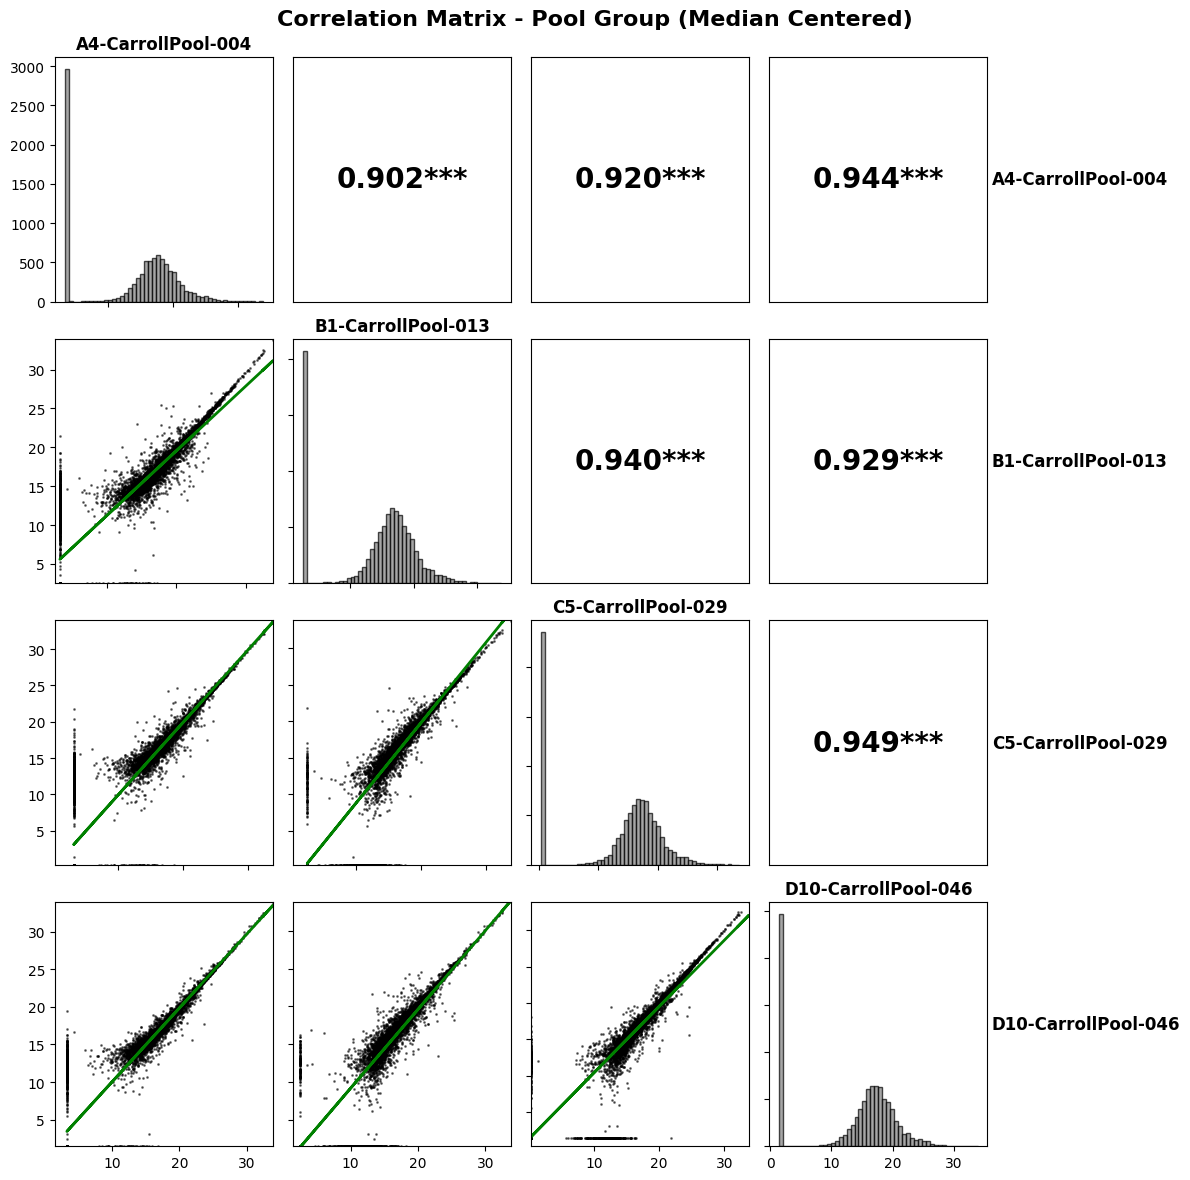

Creating correlation matrix for Carl with 4 samples (Median Centered)
Samples: ['A9-CarlC57BL-009', 'B11-CarlC57BL-023', 'C3-CarlC57BL-027', 'D6-CarlC57BL-042']


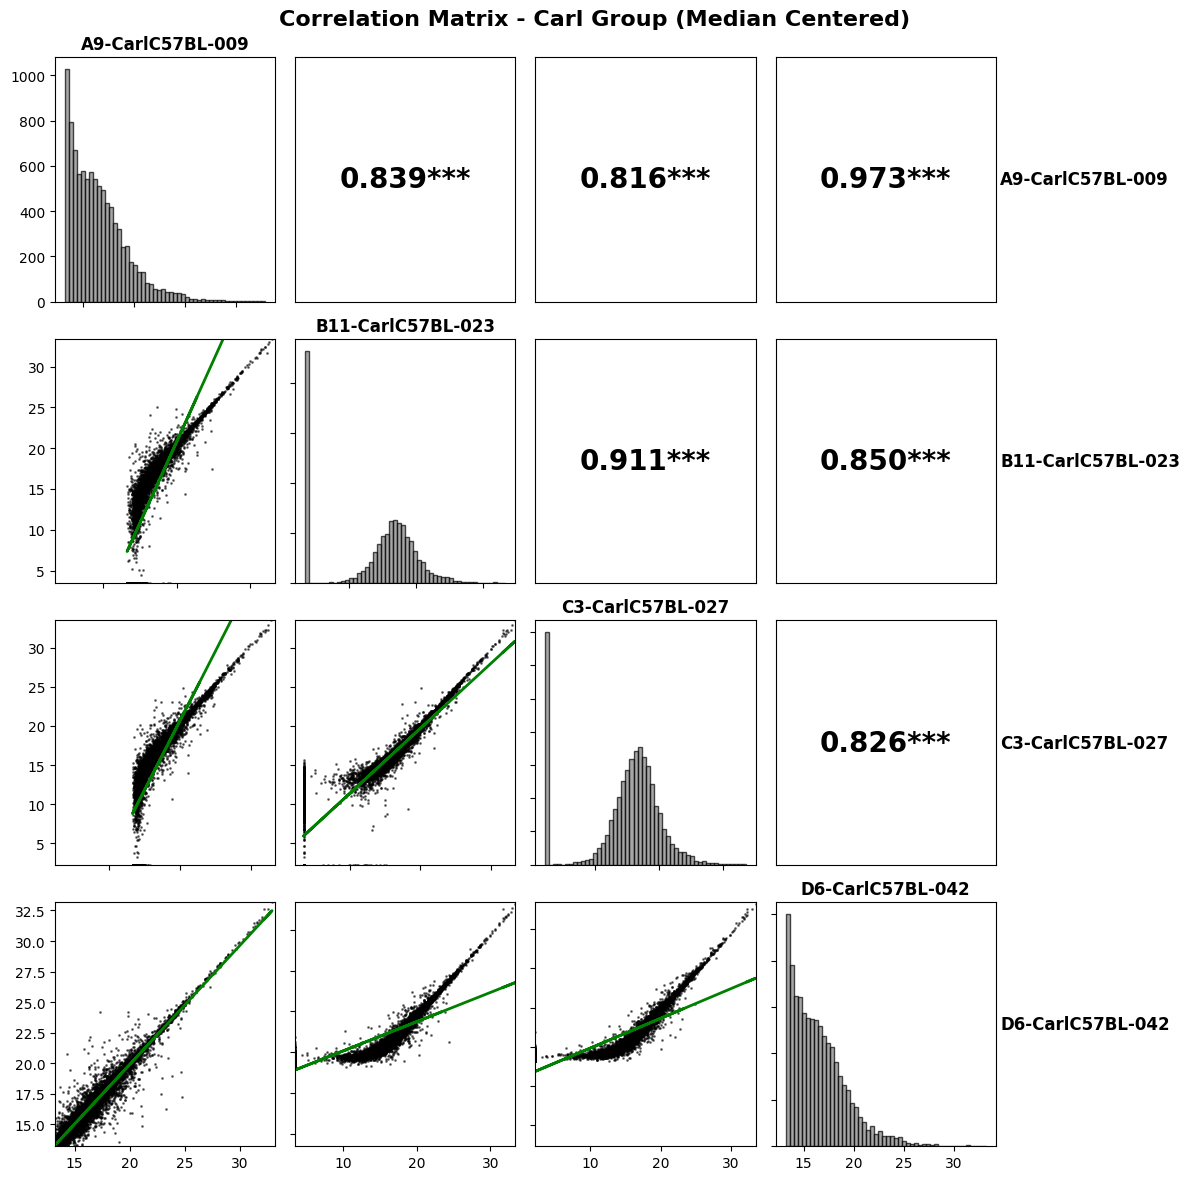

In [42]:
# Create correlation matrix for Pool and Carl groups using median centered data
def create_correlation_matrix_plot_centered(data, group_name, samples_df):
    """
    Create a correlation matrix plot using median centered data
    """
    # Get sample columns (all columns except the first 3 metadata columns)
    sample_cols = data.columns[3:]  # Skip Protein, Protein Description, Protein Gene
    
    # Get column names for the specified group
    group_replicates = samples_df['Replicate'].tolist()
    group_cols = [col for col in sample_cols if any(rep in col for rep in group_replicates)]
    
    if len(group_cols) < 2:
        print(f"Not enough samples found for {group_name} group")
        return
    
    print(f"Creating correlation matrix for {group_name} with {len(group_cols)} samples (Median Centered)")
    print(f"Samples: {[col.replace(' Sum Normalized Area', '') for col in group_cols]}")
    
    # Extract median centered data for these samples
    subset_data = data[group_cols].copy()
    
    # Remove rows with all NaN values
    subset_data = subset_data.dropna(how='all')
    
    # Fill remaining NaN values with 0 (or use another strategy)
    subset_data = subset_data.fillna(0)
    
    # Handle zero/negative values before log transformation (same as in median centering cell)
    log2_data_list = []
    
    for col in group_cols:
        col_data = subset_data[col].copy()
        
        # Replace values <= 0 with a small positive value
        min_positive = col_data[col_data > 0].min() if (col_data > 0).any() else 1
        pseudocount = min_positive / 2
        col_data = np.where(col_data <= 0, pseudocount, col_data)
        
        # Apply log2 transformation without adding 1 (since we handled zeros above)
        log2_values = np.log2(col_data)
        log2_data_list.append(log2_values)
    
    # Create DataFrame with log2 transformed data
    log2_data = pd.DataFrame(dict(zip(group_cols, log2_data_list)))
    
    # Create short names for samples
    short_names = [col.replace(' Sum Normalized Area', '').replace('EV-', '') for col in group_cols]
    log2_data.columns = short_names
    
    # Calculate correlation matrix
    corr_matrix = log2_data.corr()
    
    # Create the figure
    n_samples = len(group_cols)
    fig, axes = plt.subplots(n_samples, n_samples, figsize=(3*n_samples, 3*n_samples))
    
    if n_samples == 1:
        axes = np.array([[axes]])
    elif n_samples == 2:
        axes = axes.reshape(2, 2)
    
    for i in range(n_samples):
        for j in range(n_samples):
            ax = axes[i, j]
            
            if i == j:
                # Diagonal: histogram
                ax.hist(log2_data.iloc[:, i], bins=50, color='gray', alpha=0.7, edgecolor='black')
                ax.set_title(short_names[i], fontsize=12, fontweight='bold')
                ax.set_xlabel('')
                ax.set_ylabel('')
                
            elif i > j:
                # Lower triangle: scatter plot
                x_data = log2_data.iloc[:, j]
                y_data = log2_data.iloc[:, i]
                
                # Remove pairs where either value is invalid
                valid_mask = (x_data.notna()) & (y_data.notna()) & (x_data != -np.inf) & (y_data != -np.inf)
                x_clean = x_data[valid_mask]
                y_clean = y_data[valid_mask]
                
                ax.scatter(x_clean, y_clean, alpha=0.5, s=1, color='black')
                
                # Add regression line
                if len(x_clean) > 10:  # Only if we have enough points
                    z = np.polyfit(x_clean, y_clean, 1)
                    p = np.poly1d(z)
                    ax.plot(x_clean, p(x_clean), "g-", linewidth=2)
                
                # Set axis limits to be the same
                all_values = np.concatenate([x_clean, y_clean])
                if len(all_values) > 0:
                    min_val, max_val = all_values.min(), all_values.max()
                    ax.set_xlim(min_val, max_val)
                    ax.set_ylim(min_val, max_val)
                
                ax.set_xlabel('')
                ax.set_ylabel('')
                
            else:
                # Upper triangle: correlation coefficient
                corr_val = corr_matrix.iloc[i, j]
                ax.text(0.5, 0.5, f'{corr_val:.3f}***', 
                       horizontalalignment='center', verticalalignment='center',
                       fontsize=20, fontweight='bold', transform=ax.transAxes)
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 1)
                ax.set_xticks([])
                ax.set_yticks([])
            
            # Remove tick labels for cleaner look
            if i < n_samples - 1:
                ax.set_xticklabels([])
            if j > 0:
                ax.set_yticklabels([])
    
    # Add sample names on the right side
    for i in range(n_samples):
        ax_right = axes[i, -1]
        ax_right.text(1.02, 0.5, short_names[i], rotation=0, 
                     verticalalignment='center', transform=ax_right.transAxes,
                     fontsize=12, fontweight='bold')
    
    plt.suptitle(f'Correlation Matrix - {group_name} Group (Median Centered)', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return corr_matrix

# Create correlation matrix for Pool group using median centered data
if len(pool_samples) > 0:
    pool_corr_centered = create_correlation_matrix_plot_centered(centered_protein_data, "Pool", pool_samples)
else:
    print("No Pool samples found")

# Create correlation matrix for Carl group using median centered data
if len(carl_samples) > 0:
    carl_corr_centered = create_correlation_matrix_plot_centered(centered_protein_data, "Carl", carl_samples)
else:
    print("No Carl samples found")

This is a box plot of the median scaled data.  

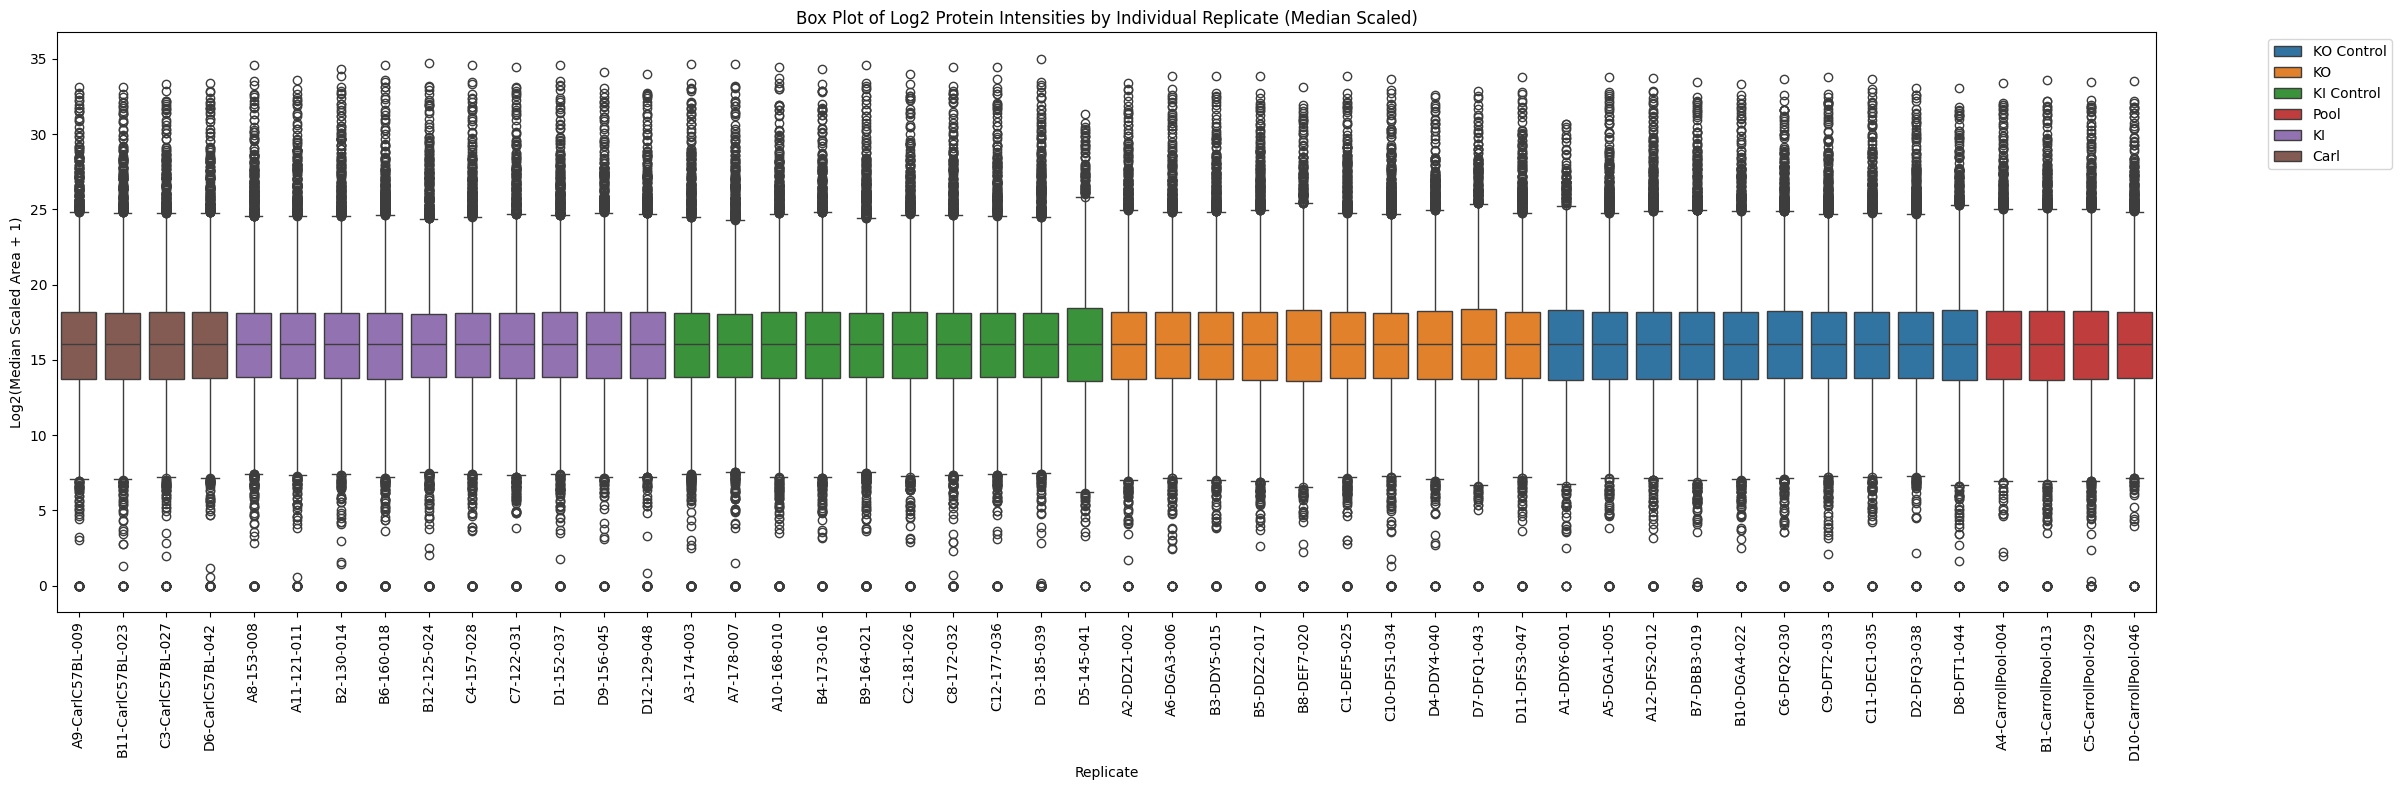

Median scaling normalization completed
Median of replicate medians (scaling factor): 66785.5
Data range after median scaling: 0.000 to 35.006


In [43]:
# Perform median scaling normalization on the protein data
median_scaled_protein_data = protein_data.copy()

# Calculate median for each replicate
replicate_medians_scaling = {}
for col in sample_columns:
    replicate_medians_scaling[col] = np.median(protein_data[col])

# Calculate the median of replicate medians (scaling factor)
median_of_medians = np.median(list(replicate_medians_scaling.values()))

# Apply median scaling: (value / replicate_median) * median_of_medians
for col in sample_columns:
    replicate_median = replicate_medians_scaling[col]
    median_scaled_protein_data[col] = (protein_data[col] / replicate_median) * median_of_medians

# Create median scaled plot data
median_scaled_plot_data = []

for col in sample_columns:
    # Extract replicate name from column name
    replicate = col.replace(' Sum Normalized Area', '')
    
    # Find the corresponding group from metadata
    group = metadata[metadata['Replicate'] == replicate]['Group'].iloc[0] if len(metadata[metadata['Replicate'] == replicate]) > 0 else 'Unknown'
    
    # Extract sample number
    sample_number = int(replicate[-3:]) if replicate[-3:].isdigit() else 0
    
    # Get log2 values (add small constant to avoid log(0))
    log2_values = np.log2(median_scaled_protein_data[col] + 1)
    
    # Add to plot data
    for value in log2_values:
        median_scaled_plot_data.append({
            'Replicate': replicate, 
            'Group': group, 
            'Sample_Number': sample_number,
            'Log2_Intensity': value
        })

# Convert to dataframe
median_scaled_plot_df = pd.DataFrame(median_scaled_plot_data)

# Create the box plot with median scaled data
plt.figure(figsize=(24, 8))
ax = sns.boxplot(data=median_scaled_plot_df, x='Replicate', y='Log2_Intensity', hue='Group', order=replicate_order)

# Rotate x-axis labels for better readability
plt.xticks(rotation=90)
plt.title('Box Plot of Log2 Protein Intensities by Individual Replicate (Median Scaled)')
plt.ylabel('Log2(Median Scaled Area + 1)')
plt.xlabel('Replicate')

# Move legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

print(f"Median scaling normalization completed")
print(f"Median of replicate medians (scaling factor): {median_of_medians:.1f}")
print(f"Data range after median scaling: {median_scaled_plot_df['Log2_Intensity'].min():.3f} to {median_scaled_plot_df['Log2_Intensity'].max():.3f}")

Correlation plots of Median Scaled Data

Creating correlation matrix for Pool with 4 samples (Median Scaled)
Samples: ['A4-CarrollPool-004', 'B1-CarrollPool-013', 'C5-CarrollPool-029', 'D10-CarrollPool-046']


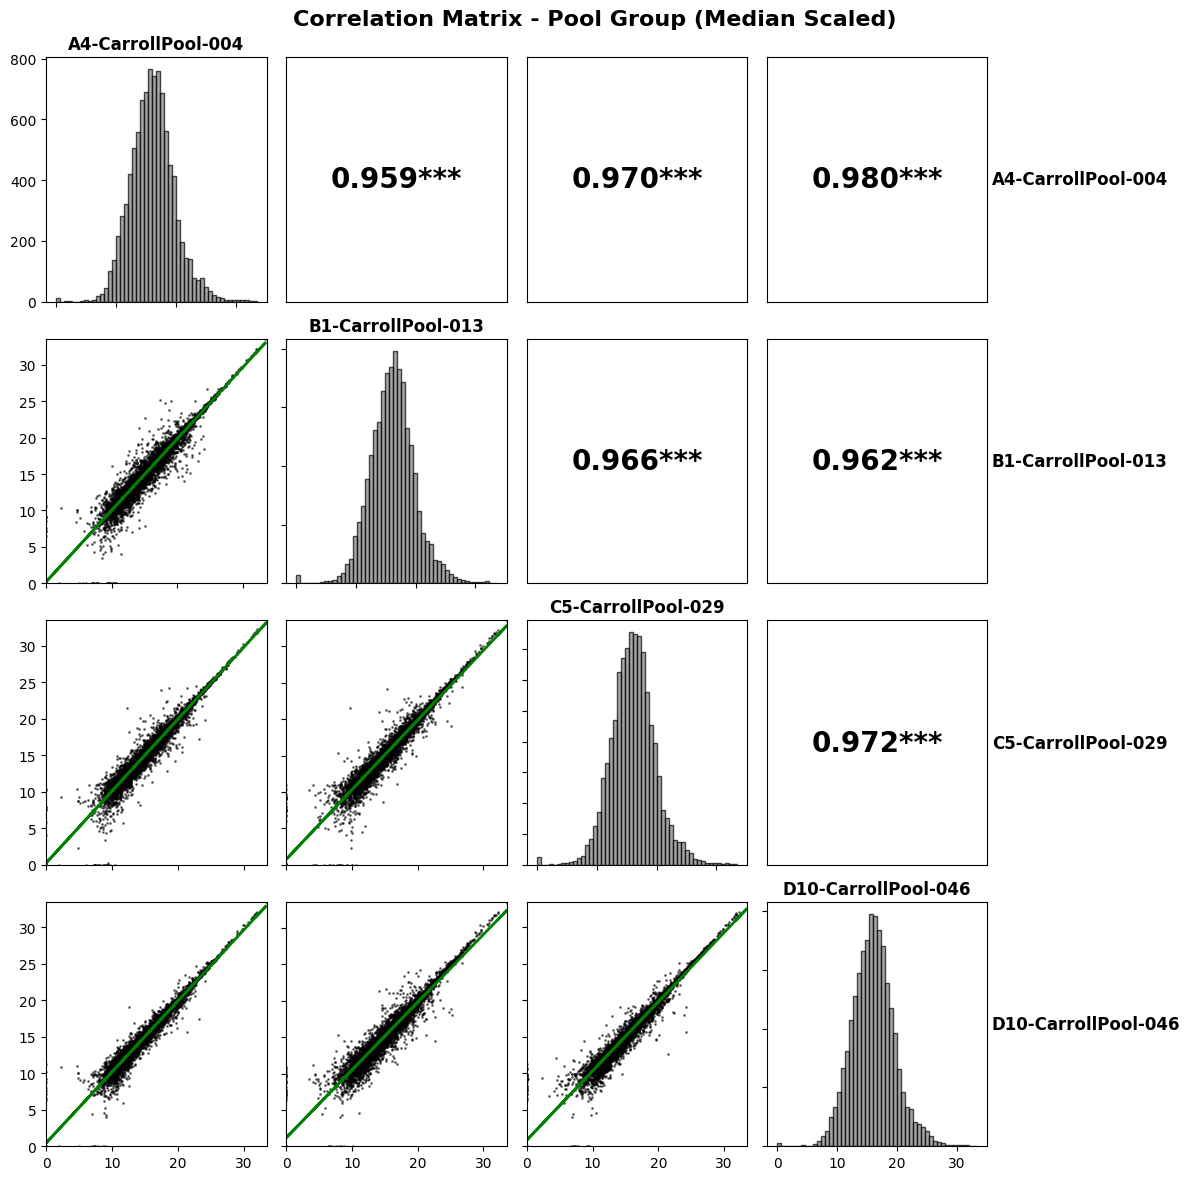

Creating correlation matrix for Carl with 4 samples (Median Scaled)
Samples: ['A9-CarlC57BL-009', 'B11-CarlC57BL-023', 'C3-CarlC57BL-027', 'D6-CarlC57BL-042']


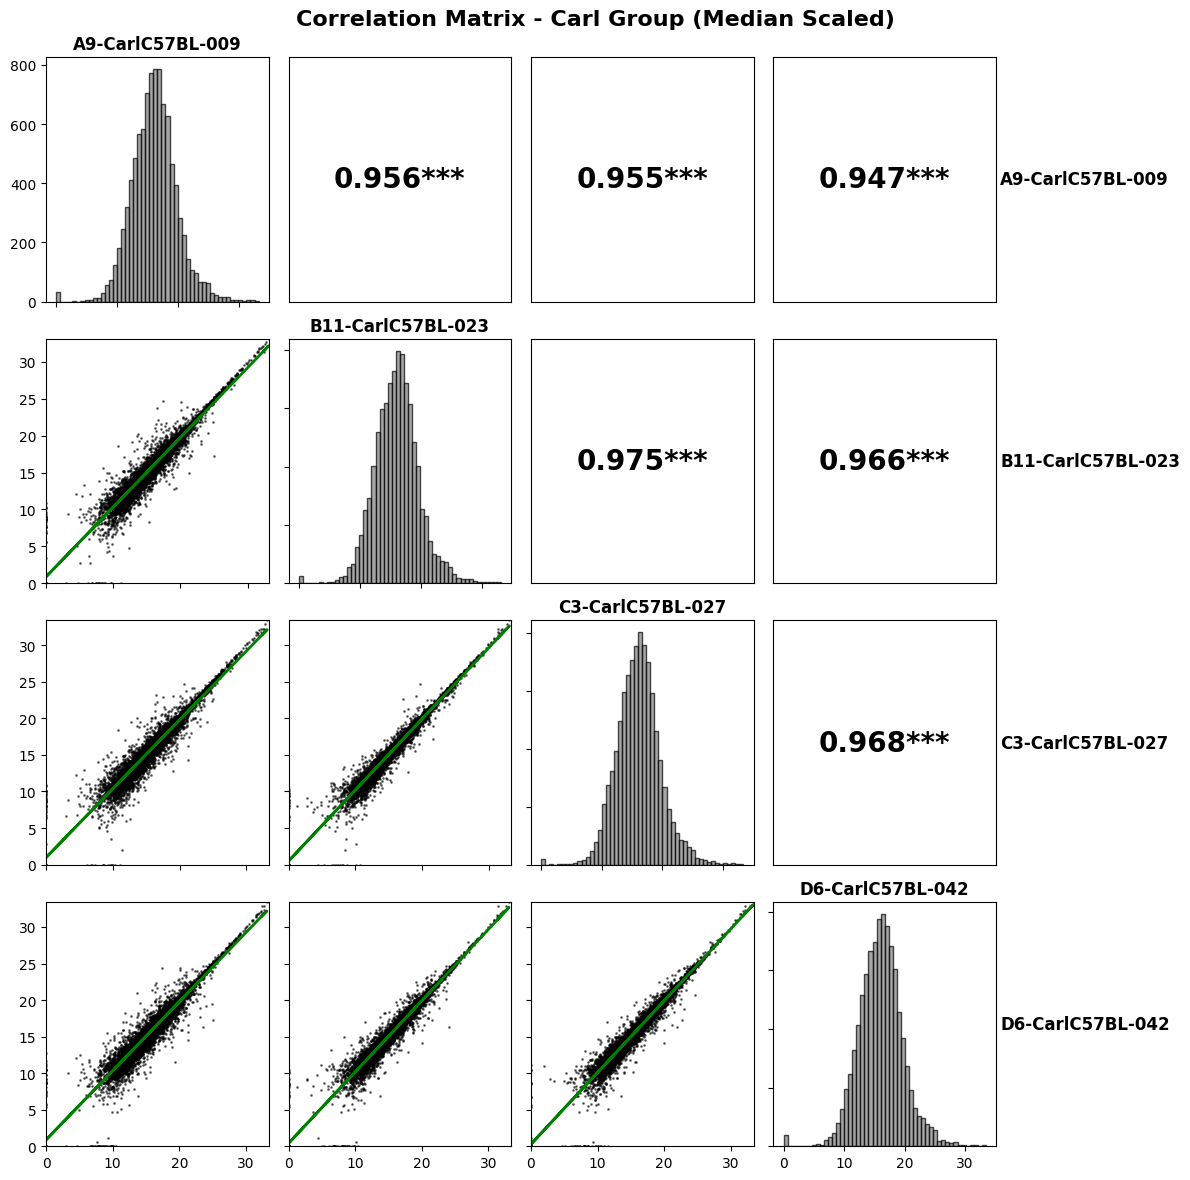

In [44]:
# Create correlation matrix for Pool and Carl groups using median scaled data
def create_correlation_matrix_plot_median_scaled(data, group_name, samples_df):
    """
    Create a correlation matrix plot using median scaled data
    """
    # Get sample columns (all columns except the first 3 metadata columns)
    sample_cols = data.columns[3:]  # Skip Protein, Protein Description, Protein Gene
    
    # Get column names for the specified group
    group_replicates = samples_df['Replicate'].tolist()
    group_cols = [col for col in sample_cols if any(rep in col for rep in group_replicates)]
    
    if len(group_cols) < 2:
        print(f"Not enough samples found for {group_name} group")
        return
    
    print(f"Creating correlation matrix for {group_name} with {len(group_cols)} samples (Median Scaled)")
    print(f"Samples: {[col.replace(' Sum Normalized Area', '') for col in group_cols]}")
    
    # Extract median scaled data for these samples
    subset_data = data[group_cols].copy()
    
    # Remove rows with all NaN values
    subset_data = subset_data.dropna(how='all')
    
    # Fill remaining NaN values with 0 (or use another strategy)
    subset_data = subset_data.fillna(0)
    
    # Apply log2 transformation (add small constant to avoid log(0))
    log2_data = np.log2(subset_data + 1)
    
    # Create short names for samples
    short_names = [col.replace(' Sum Normalized Area', '').replace('EV-', '') for col in group_cols]
    log2_data.columns = short_names
    
    # Calculate correlation matrix
    corr_matrix = log2_data.corr()
    
    # Create the figure
    n_samples = len(group_cols)
    fig, axes = plt.subplots(n_samples, n_samples, figsize=(3*n_samples, 3*n_samples))
    
    if n_samples == 1:
        axes = np.array([[axes]])
    elif n_samples == 2:
        axes = axes.reshape(2, 2)
    
    for i in range(n_samples):
        for j in range(n_samples):
            ax = axes[i, j]
            
            if i == j:
                # Diagonal: histogram
                ax.hist(log2_data.iloc[:, i], bins=50, color='gray', alpha=0.7, edgecolor='black')
                ax.set_title(short_names[i], fontsize=12, fontweight='bold')
                ax.set_xlabel('')
                ax.set_ylabel('')
                
            elif i > j:
                # Lower triangle: scatter plot
                x_data = log2_data.iloc[:, j]
                y_data = log2_data.iloc[:, i]
                
                # Remove pairs where either value is invalid
                valid_mask = (x_data.notna()) & (y_data.notna()) & (x_data != -np.inf) & (y_data != -np.inf)
                x_clean = x_data[valid_mask]
                y_clean = y_data[valid_mask]
                
                ax.scatter(x_clean, y_clean, alpha=0.5, s=1, color='black')
                
                # Add regression line
                if len(x_clean) > 10:  # Only if we have enough points
                    z = np.polyfit(x_clean, y_clean, 1)
                    p = np.poly1d(z)
                    ax.plot(x_clean, p(x_clean), "g-", linewidth=2)
                
                # Set axis limits to be the same
                all_values = np.concatenate([x_clean, y_clean])
                if len(all_values) > 0:
                    min_val, max_val = all_values.min(), all_values.max()
                    ax.set_xlim(min_val, max_val)
                    ax.set_ylim(min_val, max_val)
                
                ax.set_xlabel('')
                ax.set_ylabel('')
                
            else:
                # Upper triangle: correlation coefficient
                corr_val = corr_matrix.iloc[i, j]
                ax.text(0.5, 0.5, f'{corr_val:.3f}***', 
                       horizontalalignment='center', verticalalignment='center',
                       fontsize=20, fontweight='bold', transform=ax.transAxes)
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 1)
                ax.set_xticks([])
                ax.set_yticks([])
            
            # Remove tick labels for cleaner look
            if i < n_samples - 1:
                ax.set_xticklabels([])
            if j > 0:
                ax.set_yticklabels([])
    
    # Add sample names on the right side
    for i in range(n_samples):
        ax_right = axes[i, -1]
        ax_right.text(1.02, 0.5, short_names[i], rotation=0, 
                     verticalalignment='center', transform=ax_right.transAxes,
                     fontsize=12, fontweight='bold')
    
    plt.suptitle(f'Correlation Matrix - {group_name} Group (Median Scaled)', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return corr_matrix

# Create correlation matrix for Pool group using median scaled data
if len(pool_samples) > 0:
    pool_corr_median_scaled = create_correlation_matrix_plot_median_scaled(median_scaled_protein_data, "Pool", pool_samples)
else:
    print("No Pool samples found")

# Create correlation matrix for Carl group using median scaled data
if len(carl_samples) > 0:
    carl_corr_median_scaled = create_correlation_matrix_plot_median_scaled(median_scaled_protein_data, "Carl", carl_samples)
else:
    print("No Carl samples found")

Boxplot of VSN normalized protein intensities using a 0.5 quantile. Supposedly the inverse hyperbolic sine (IHS) transformation is often applied to handle data that is right-skewed and contains zeros. It is a type of variance stablizing transformation.

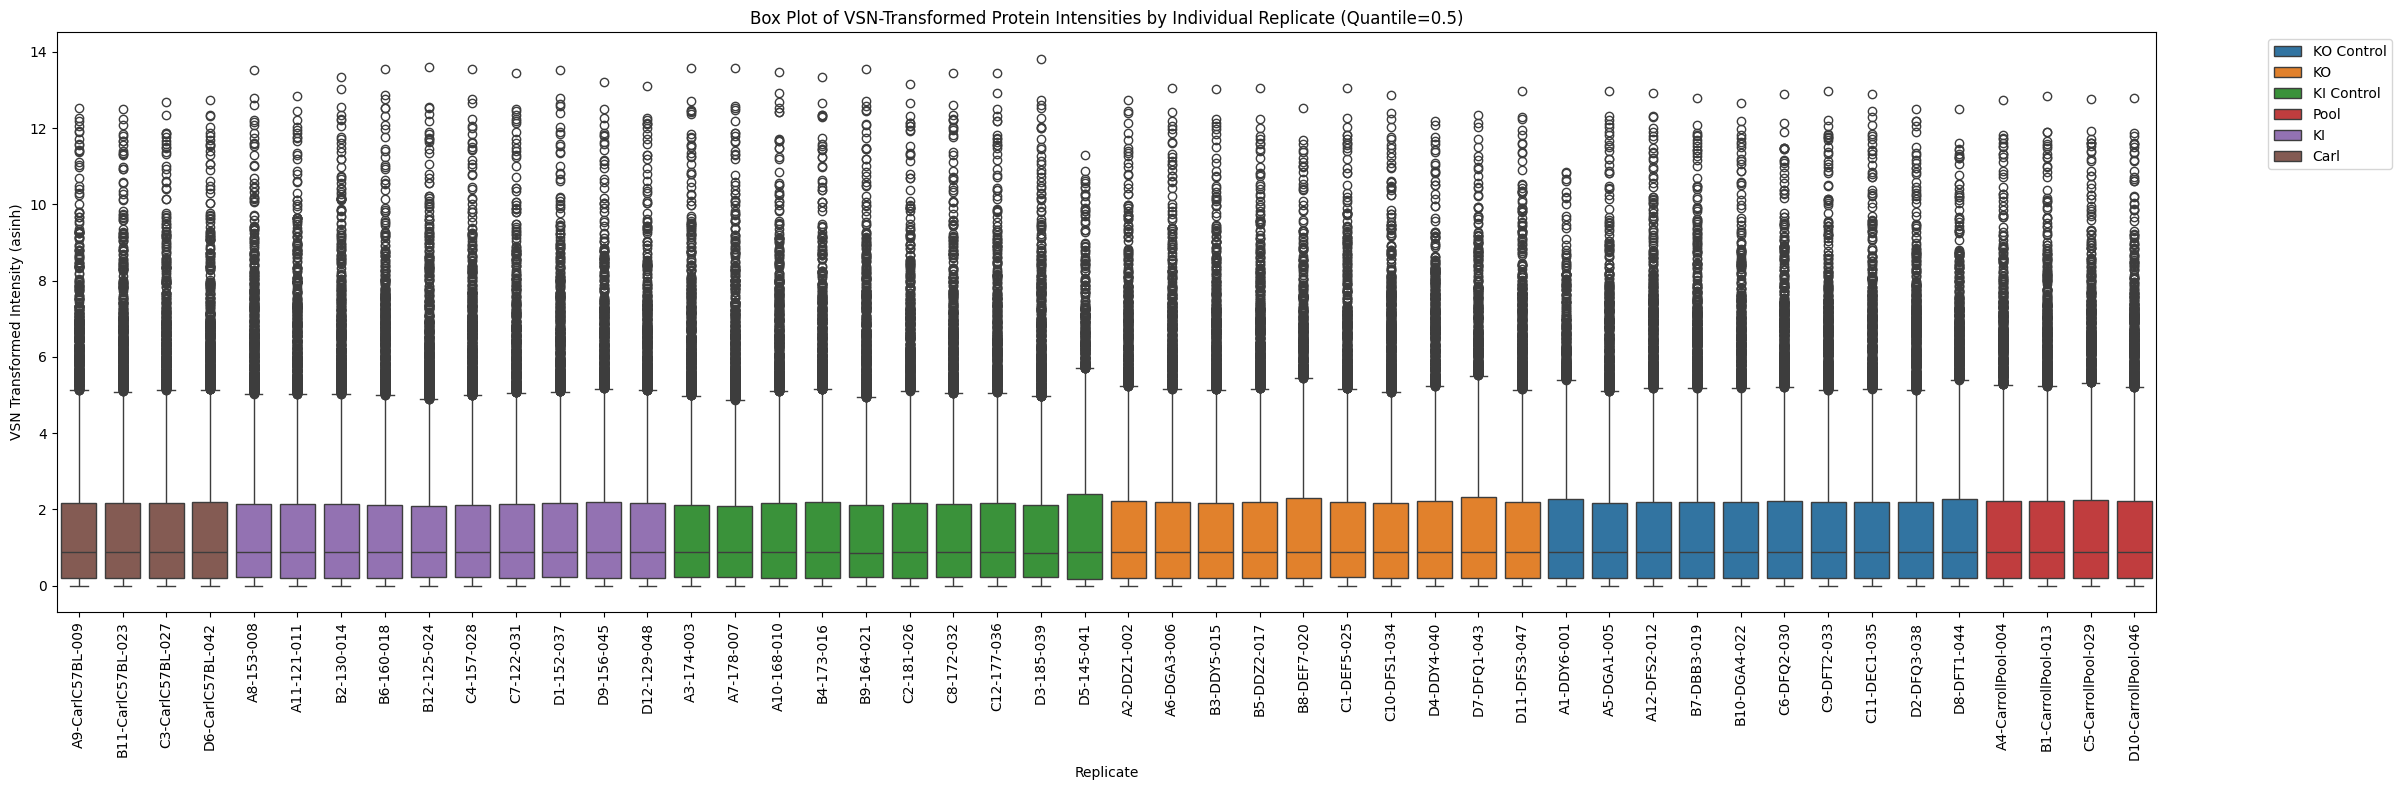

VSN transformation completed using asinh method with quantile=0.5
Data range after VSN: 0.000 to 13.824


In [45]:
from scipy import optimize
import warnings

# Perform VSN (Variance Stabilizing Normalization) on the protein data
# VSN applies a data-driven transformation to stabilize variance across the intensity range

warnings.filterwarnings('ignore')

def vsn_transformation(data, method='asinh', quantile=0.5):
    """
    Apply VSN transformation to stabilize variance
    """
    if method == 'asinh':
        # Inverse hyperbolic sine transformation (commonly used for proteomics)
        # Use quantile-based scaling factor to optimize the transformation
        scaling_factor = 1 / np.quantile(data[data > 0], quantile)
        transformed = np.arcsinh(data * scaling_factor)
    elif method == 'log2':
        # Standard log2 transformation with pseudocount
        min_positive = data[data > 0].min() if (data > 0).any() else 1
        pseudocount = min_positive / 2
        transformed = np.log2(data + pseudocount)
    else:
        # Default to asinh
        scaling_factor = 1 / np.quantile(data[data > 0], quantile)
        transformed = np.arcsinh(data * scaling_factor)
    
    return transformed

# Apply VSN transformation to the protein data
vsn_protein_data = protein_data.copy()

# Apply VSN transformation to each sample column with quantile=0.5
for col in sample_columns:
    vsn_protein_data[col] = vsn_transformation(protein_data[col].values, method='asinh', quantile=0.5)

# Create VSN plot data
vsn_plot_data = []

for col in sample_columns:
    # Extract replicate name from column name
    replicate = col.replace(' Sum Normalized Area', '')
    
    # Find the corresponding group from metadata
    group = metadata[metadata['Replicate'] == replicate]['Group'].iloc[0] if len(metadata[metadata['Replicate'] == replicate]) > 0 else 'Unknown'
    
    # Extract sample number
    sample_number = int(replicate[-3:]) if replicate[-3:].isdigit() else 0
    
    # Get VSN transformed values
    vsn_values = vsn_protein_data[col]
    
    # Add to plot data
    for value in vsn_values:
        vsn_plot_data.append({
            'Replicate': replicate, 
            'Group': group, 
            'Sample_Number': sample_number,
            'VSN_Intensity': value
        })

# Convert to dataframe
vsn_plot_df = pd.DataFrame(vsn_plot_data)

# Create the box plot with VSN-transformed data
plt.figure(figsize=(24, 8))
ax = sns.boxplot(data=vsn_plot_df, x='Replicate', y='VSN_Intensity', hue='Group', order=replicate_order)

# Rotate x-axis labels for better readability
plt.xticks(rotation=90)
plt.title('Box Plot of VSN-Transformed Protein Intensities by Individual Replicate (Quantile=0.5)')
plt.ylabel('VSN Transformed Intensity (asinh)')
plt.xlabel('Replicate')

# Move legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

print(f"VSN transformation completed using asinh method with quantile=0.5")
print(f"Data range after VSN: {vsn_plot_df['VSN_Intensity'].min():.3f} to {vsn_plot_df['VSN_Intensity'].max():.3f}")

Creating correlation matrix for Pool with 4 samples (VSN Normalized)
Samples: ['A4-CarrollPool-004', 'B1-CarrollPool-013', 'C5-CarrollPool-029', 'D10-CarrollPool-046']


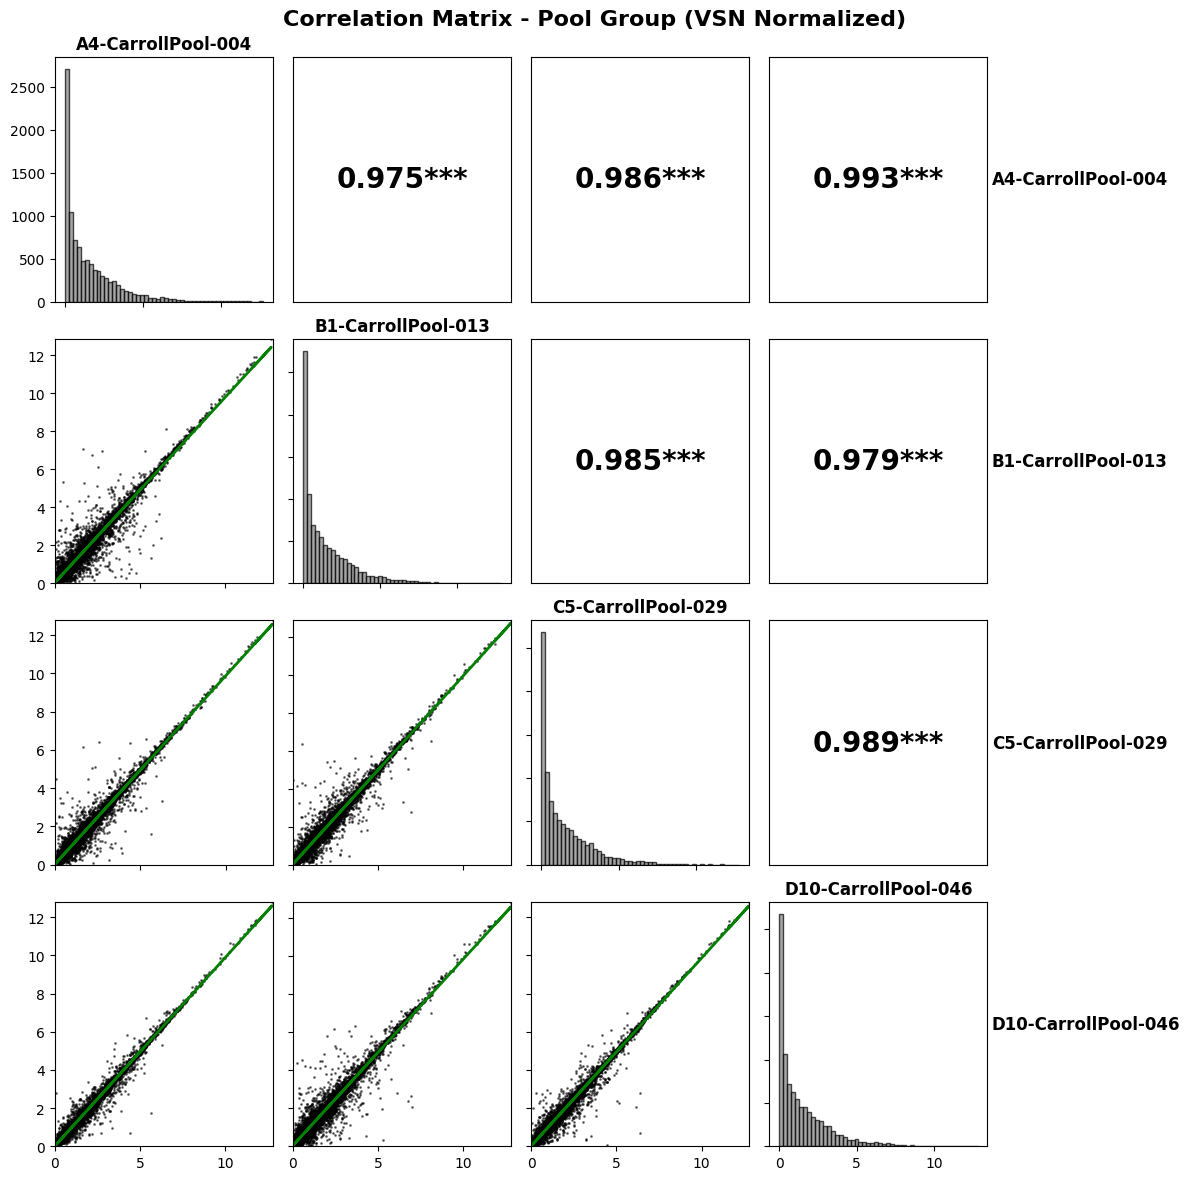

Creating correlation matrix for Carl with 4 samples (VSN Normalized)
Samples: ['A9-CarlC57BL-009', 'B11-CarlC57BL-023', 'C3-CarlC57BL-027', 'D6-CarlC57BL-042']


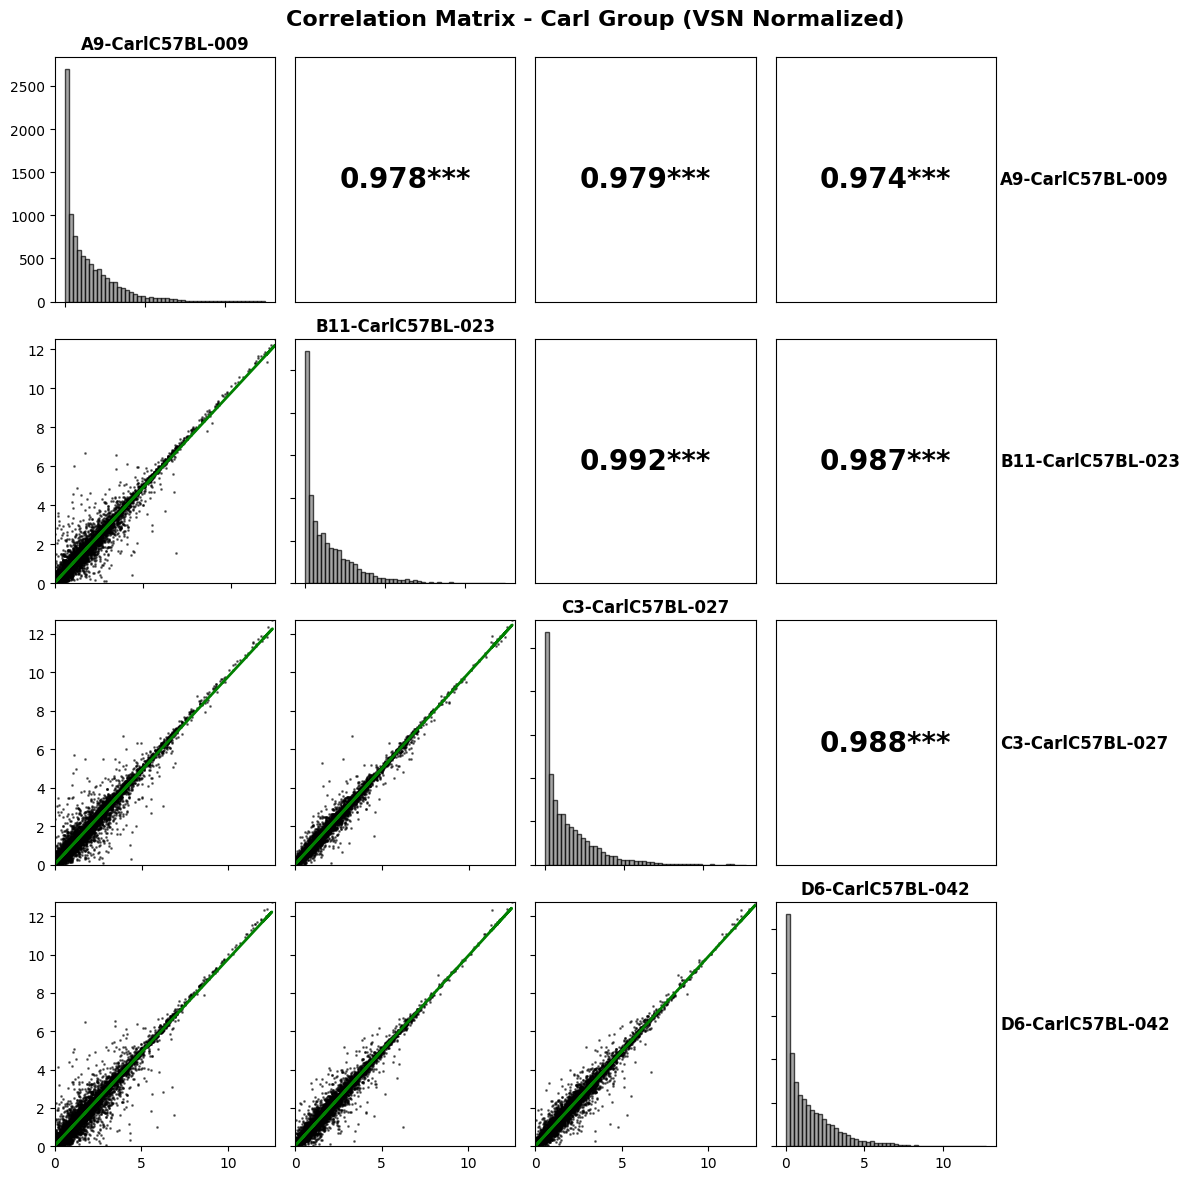

In [46]:
# Create correlation matrix for Pool and Carl groups using VSN normalized data
def create_correlation_matrix_plot_vsn(data, group_name, samples_df):
    """
    Create a correlation matrix plot using VSN normalized data
    """
    # Get sample columns (all columns except the first 3 metadata columns)
    sample_cols = data.columns[3:]  # Skip Protein, Protein Description, Protein Gene
    
    # Get column names for the specified group
    group_replicates = samples_df['Replicate'].tolist()
    group_cols = [col for col in sample_cols if any(rep in col for rep in group_replicates)]
    
    if len(group_cols) < 2:
        print(f"Not enough samples found for {group_name} group")
        return
    
    print(f"Creating correlation matrix for {group_name} with {len(group_cols)} samples (VSN Normalized)")
    print(f"Samples: {[col.replace(' Sum Normalized Area', '') for col in group_cols]}")
    
    # Extract VSN normalized data for these samples
    subset_data = data[group_cols].copy()
    
    # Remove rows with all NaN values
    subset_data = subset_data.dropna(how='all')
    
    # Fill remaining NaN values with 0 (or use another strategy)
    subset_data = subset_data.fillna(0)
    
    # VSN data is already transformed, no need for additional log transformation
    vsn_data = subset_data.copy()
    
    # Create short names for samples
    short_names = [col.replace(' Sum Normalized Area', '').replace('EV-', '') for col in group_cols]
    vsn_data.columns = short_names
    
    # Calculate correlation matrix
    corr_matrix = vsn_data.corr()
    
    # Create the figure
    n_samples = len(group_cols)
    fig, axes = plt.subplots(n_samples, n_samples, figsize=(3*n_samples, 3*n_samples))
    
    if n_samples == 1:
        axes = np.array([[axes]])
    elif n_samples == 2:
        axes = axes.reshape(2, 2)
    
    for i in range(n_samples):
        for j in range(n_samples):
            ax = axes[i, j]
            
            if i == j:
                # Diagonal: histogram
                ax.hist(vsn_data.iloc[:, i], bins=50, color='gray', alpha=0.7, edgecolor='black')
                ax.set_title(short_names[i], fontsize=12, fontweight='bold')
                ax.set_xlabel('')
                ax.set_ylabel('')
                
            elif i > j:
                # Lower triangle: scatter plot
                x_data = vsn_data.iloc[:, j]
                y_data = vsn_data.iloc[:, i]
                
                # Remove pairs where either value is invalid
                valid_mask = (x_data.notna()) & (y_data.notna()) & (x_data != -np.inf) & (y_data != -np.inf)
                x_clean = x_data[valid_mask]
                y_clean = y_data[valid_mask]
                
                ax.scatter(x_clean, y_clean, alpha=0.5, s=1, color='black')
                
                # Add regression line
                if len(x_clean) > 10:  # Only if we have enough points
                    z = np.polyfit(x_clean, y_clean, 1)
                    p = np.poly1d(z)
                    ax.plot(x_clean, p(x_clean), "g-", linewidth=2)
                
                # Set axis limits to be the same
                all_values = np.concatenate([x_clean, y_clean])
                if len(all_values) > 0:
                    min_val, max_val = all_values.min(), all_values.max()
                    ax.set_xlim(min_val, max_val)
                    ax.set_ylim(min_val, max_val)
                
                ax.set_xlabel('')
                ax.set_ylabel('')
                
            else:
                # Upper triangle: correlation coefficient
                corr_val = corr_matrix.iloc[i, j]
                ax.text(0.5, 0.5, f'{corr_val:.3f}***', 
                       horizontalalignment='center', verticalalignment='center',
                       fontsize=20, fontweight='bold', transform=ax.transAxes)
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 1)
                ax.set_xticks([])
                ax.set_yticks([])
            
            # Remove tick labels for cleaner look
            if i < n_samples - 1:
                ax.set_xticklabels([])
            if j > 0:
                ax.set_yticklabels([])
    
    # Add sample names on the right side
    for i in range(n_samples):
        ax_right = axes[i, -1]
        ax_right.text(1.02, 0.5, short_names[i], rotation=0, 
                     verticalalignment='center', transform=ax_right.transAxes,
                     fontsize=12, fontweight='bold')
    
    plt.suptitle(f'Correlation Matrix - {group_name} Group (VSN Normalized)', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return corr_matrix

# Create correlation matrix for Pool group using VSN normalized data
if len(pool_samples) > 0:
    pool_corr_vsn = create_correlation_matrix_plot_vsn(vsn_protein_data, "Pool", pool_samples)
else:
    print("No Pool samples found")

# Create correlation matrix for Carl group using VSN normalized data
if len(carl_samples) > 0:
    carl_corr_vsn = create_correlation_matrix_plot_vsn(vsn_protein_data, "Carl", carl_samples)
else:
    print("No Carl samples found")

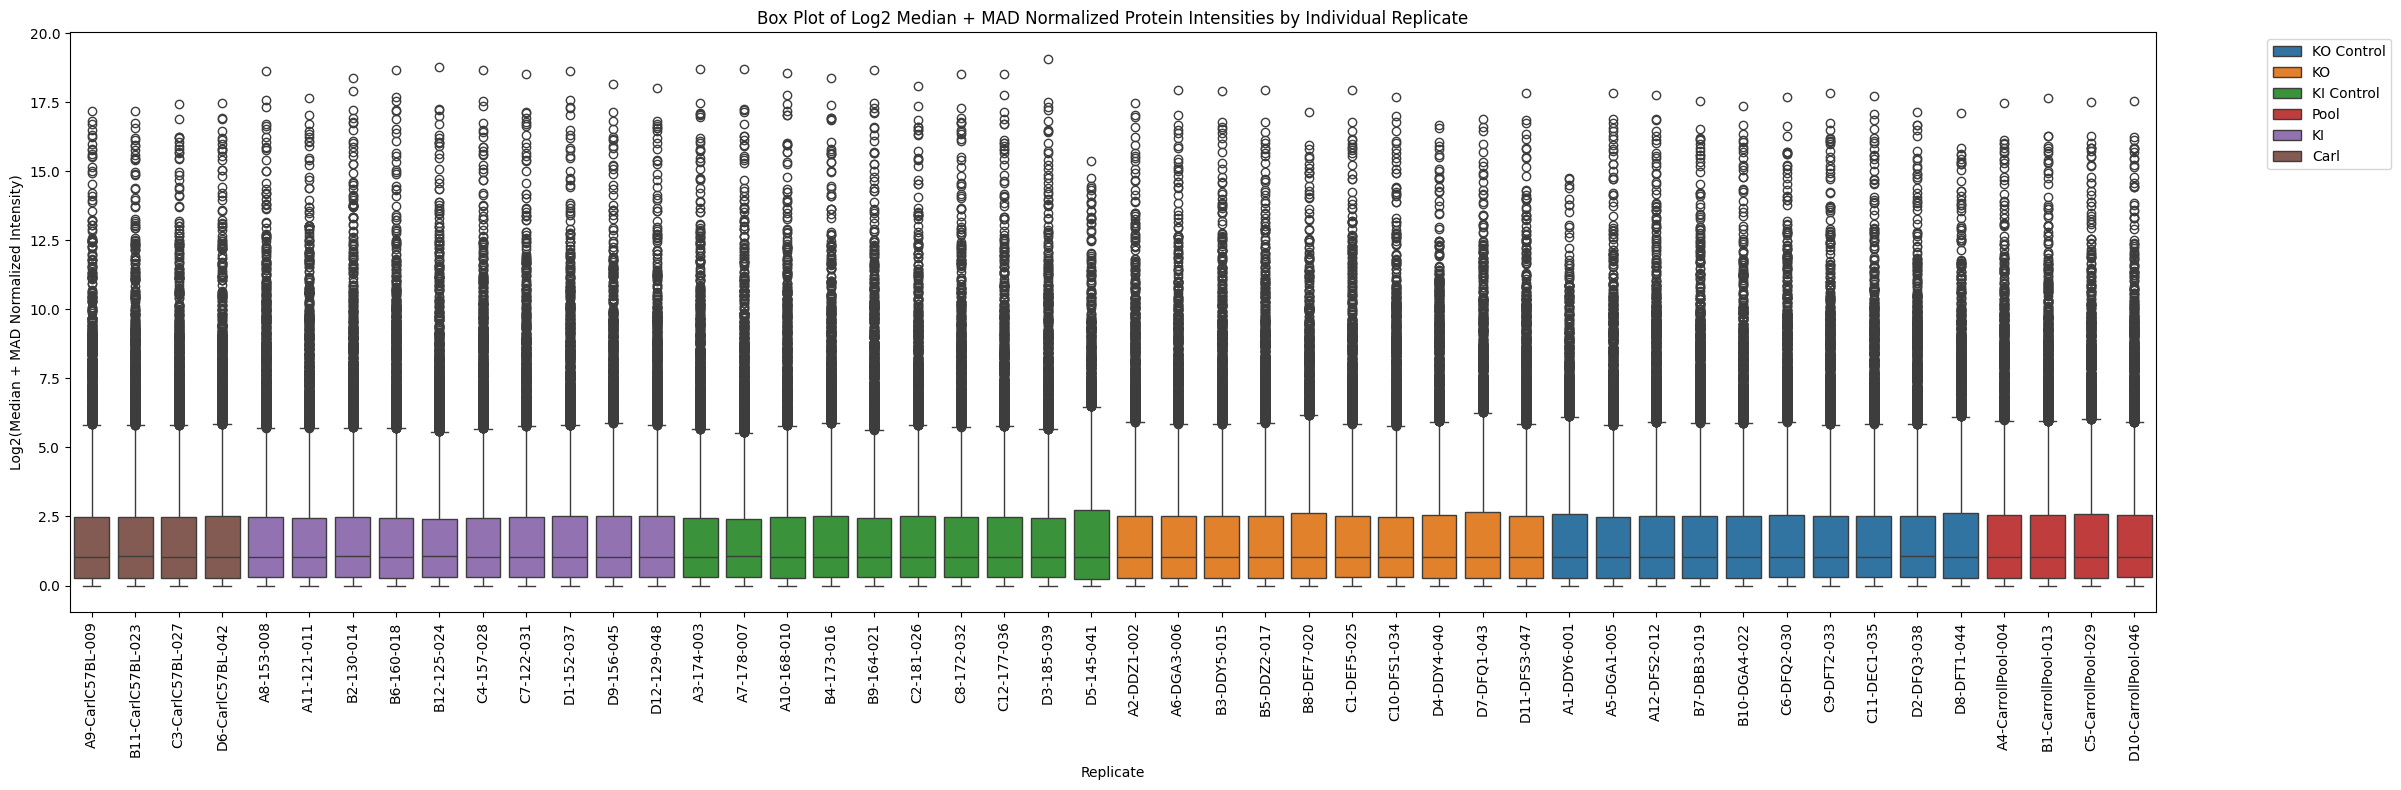

Median + MAD normalization with Log2 transformation completed
Data range after Log2 MAD normalization: -0.000 to 19.076


In [47]:
from scipy import stats

# Perform median + MAD normalization on the protein data
mad_protein_data = protein_data.copy()

def median_mad_normalization(data_series):
    """
    Apply median + MAD (Median Absolute Deviation) normalization
    """
    # Calculate median and MAD
    median_val = np.median(data_series)
    mad_val = stats.median_abs_deviation(data_series, nan_policy='omit')
    
    # Avoid division by zero
    if mad_val == 0:
        mad_val = 1
    
    # Normalize: (x - median) / MAD
    normalized = (data_series - median_val) / mad_val
    
    return normalized

# Apply median + MAD normalization to each sample column
for col in sample_columns:
    mad_protein_data[col] = median_mad_normalization(protein_data[col].values)

# Create MAD normalized plot data
mad_plot_data = []

for col in sample_columns:
    # Extract replicate name from column name
    replicate = col.replace(' Sum Normalized Area', '')
    
    # Find the corresponding group from metadata
    group = metadata[metadata['Replicate'] == replicate]['Group'].iloc[0] if len(metadata[metadata['Replicate'] == replicate]) > 0 else 'Unknown'
    
    # Extract sample number
    sample_number = int(replicate[-3:]) if replicate[-3:].isdigit() else 0
    
    # Get MAD normalized values and apply log2 transformation
    mad_values = mad_protein_data[col]
    
    # Handle negative values that might result from normalization
    # Add an offset to make all values positive before log transformation
    min_val = mad_values.min()
    if min_val <= 0:
        offset = abs(min_val) + 1
        mad_values_positive = mad_values + offset
    else:
        mad_values_positive = mad_values
    
    # Apply log2 transformation
    log2_mad_values = np.log2(mad_values_positive)
    
    # Add to plot data
    for value in log2_mad_values:
        mad_plot_data.append({
            'Replicate': replicate, 
            'Group': group, 
            'Sample_Number': sample_number,
            'Log2_MAD_Intensity': value
        })

# Convert to dataframe
mad_plot_df = pd.DataFrame(mad_plot_data)

# Create the box plot with log2 MAD-normalized data
plt.figure(figsize=(24, 8))
ax = sns.boxplot(data=mad_plot_df, x='Replicate', y='Log2_MAD_Intensity', hue='Group', order=replicate_order)

# Rotate x-axis labels for better readability
plt.xticks(rotation=90)
plt.title('Box Plot of Log2 Median + MAD Normalized Protein Intensities by Individual Replicate')
plt.ylabel('Log2(Median + MAD Normalized Intensity)')
plt.xlabel('Replicate')

# Move legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

print(f"Median + MAD normalization with Log2 transformation completed")
print(f"Data range after Log2 MAD normalization: {mad_plot_df['Log2_MAD_Intensity'].min():.3f} to {mad_plot_df['Log2_MAD_Intensity'].max():.3f}")


[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: C:\Users\macco\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


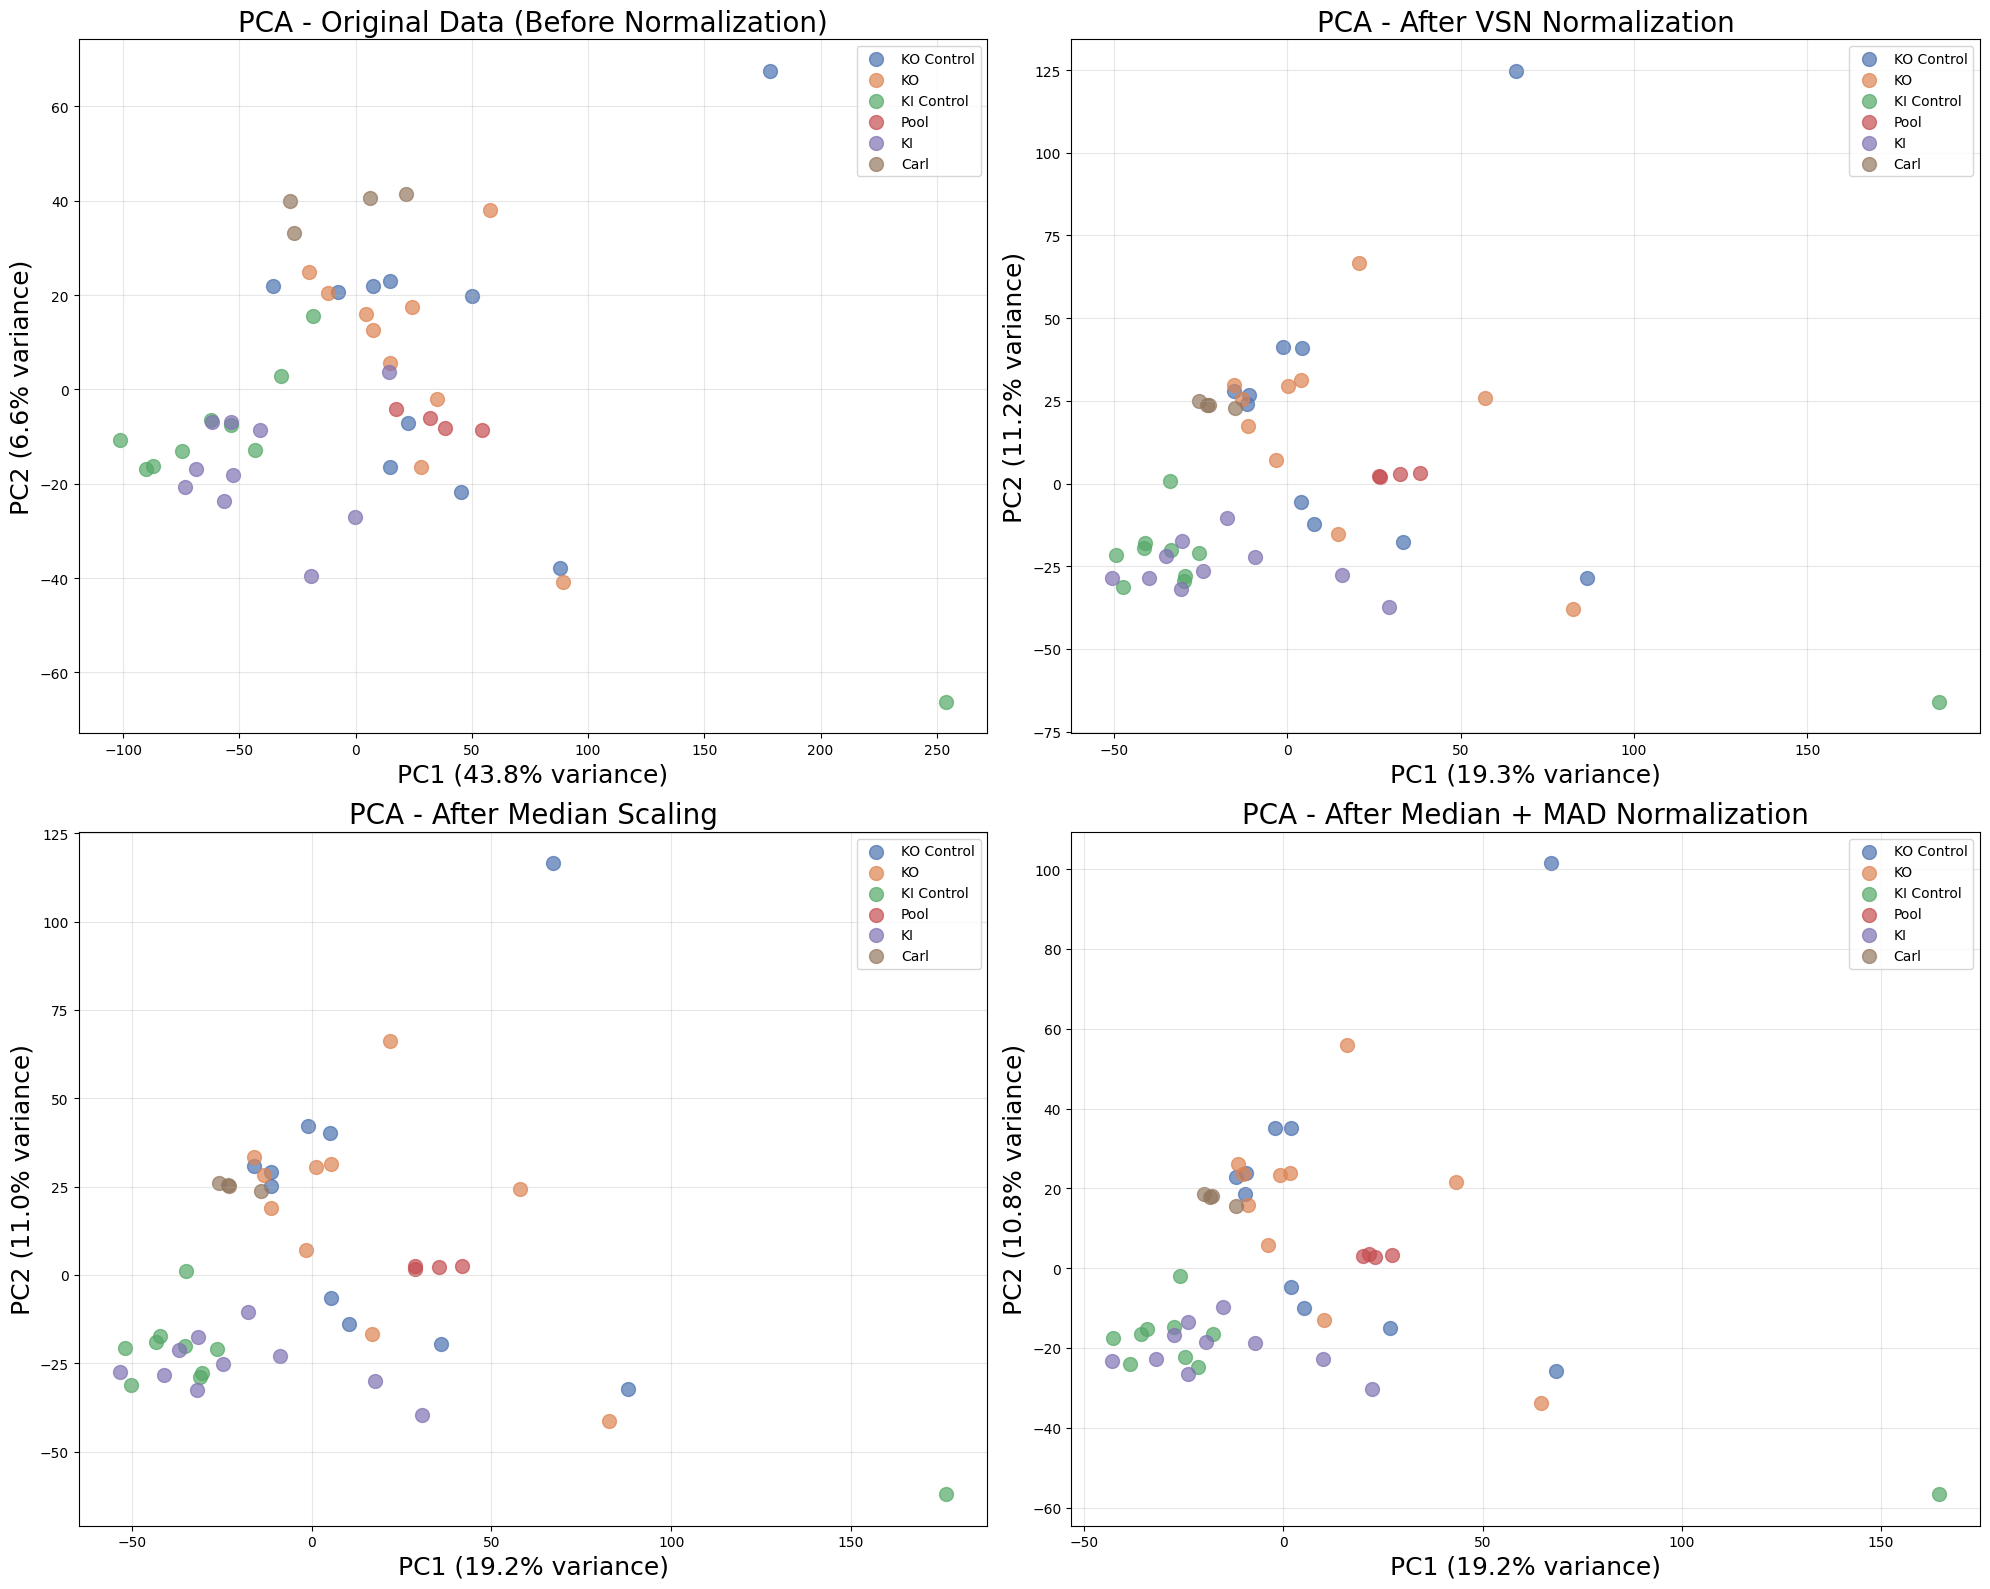

Original data - PC1: 0.438, PC2: 0.066
VSN data - PC1: 0.193, PC2: 0.112
Median scaled data - PC1: 0.192, PC2: 0.110
Median + MAD data - PC1: 0.192, PC2: 0.108


In [48]:
%pip install scikit-learn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Prepare VSN data for PCA
vsn_data_for_pca = vsn_protein_data[sample_columns].T
vsn_data_for_pca = vsn_data_for_pca.fillna(0)

# Create sample info dataframe for coloring
sample_info = []
for col in sample_columns:
    replicate = col.replace(' Sum Normalized Area', '')
    group = metadata[metadata['Replicate'] == replicate]['Group'].iloc[0] if len(metadata[metadata['Replicate'] == replicate]) > 0 else 'Unknown'
    sample_info.append({'Replicate': replicate, 'Group': group})

sample_info_df = pd.DataFrame(sample_info)

# Prepare original data for PCA
original_data_for_pca = protein_data[sample_columns].T
original_data_for_pca = original_data_for_pca.fillna(0)

# Prepare centered data for PCA
centered_data_for_pca = centered_protein_data[sample_columns].T
centered_data_for_pca = centered_data_for_pca.fillna(0)

# Prepare median + MAD normalized data for PCA
mad_data_for_pca = mad_protein_data[sample_columns].T
mad_data_for_pca = mad_data_for_pca.fillna(0)

# Function to prepare data for PCA with log transformation and standardization
def prepare_for_pca(data):
    # Handle zero/negative values before log transformation
    data_clean = data.copy()
    min_positive = data_clean[data_clean > 0].min().min() if (data_clean > 0).any().any() else 1
    pseudocount = min_positive / 10
    data_clean = np.where(data_clean <= 0, pseudocount, data_clean)
    
    # Log2 transform
    log_data = np.log2(data_clean)
    # Standardize
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(log_data)
    return scaled_data

# Prepare VSN data (no additional log transformation needed)
def prepare_vsn_for_pca(data):
    # VSN data is already transformed, just standardize
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)
    return scaled_data

# Prepare all datasets
original_scaled = prepare_for_pca(original_data_for_pca)
centered_scaled = prepare_for_pca(centered_data_for_pca)
vsn_scaled = prepare_vsn_for_pca(vsn_data_for_pca)
mad_scaled = prepare_for_pca(mad_data_for_pca)

# Prepare median scaled data for PCA
median_scaled_data_for_pca = median_scaled_protein_data[sample_columns].T
median_scaled_data_for_pca = median_scaled_data_for_pca.fillna(0)
median_scaled_scaled = prepare_for_pca(median_scaled_data_for_pca)

# Perform PCA on all datasets
pca_original = PCA(n_components=2)
original_pca_result = pca_original.fit_transform(original_scaled)
original_variance_explained = pca_original.explained_variance_ratio_

pca_median_scaled = PCA(n_components=2)
median_scaled_pca_result = pca_median_scaled.fit_transform(median_scaled_scaled)
median_scaled_variance_explained = pca_median_scaled.explained_variance_ratio_

pca_vsn = PCA(n_components=2)
vsn_pca_result = pca_vsn.fit_transform(vsn_scaled)
vsn_variance_explained = pca_vsn.explained_variance_ratio_

pca_mad = PCA(n_components=2)
mad_pca_result = pca_mad.fit_transform(mad_scaled)
mad_variance_explained = pca_mad.explained_variance_ratio_

# Create PCA plots for all four normalization methods
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 16))

# Use the same colors as in the box plot
group_names = sample_info_df['Group'].unique()
colors = sns.color_palette("deep", n_colors=len(group_names))
color_map = dict(zip(group_names, colors))

# Original data PCA
for group in sample_info_df['Group'].unique():
    mask = sample_info_df['Group'] == group
    ax1.scatter(original_pca_result[mask, 0], original_pca_result[mask, 1], 
               c=[color_map[group]], label=group, alpha=0.7, s=100)

ax1.set_xlabel(f'PC1 ({original_variance_explained[0]:.1%} variance)', fontsize=18)
ax1.set_ylabel(f'PC2 ({original_variance_explained[1]:.1%} variance)', fontsize=18)
ax1.set_title('PCA - Original Data (Before Normalization)', fontsize=20)
ax1.legend()
ax1.grid(True, alpha=0.3)

# VSN normalized data PCA
for group in sample_info_df['Group'].unique():
    mask = sample_info_df['Group'] == group
    ax2.scatter(vsn_pca_result[mask, 0], vsn_pca_result[mask, 1], 
               c=[color_map[group]], label=group, alpha=0.7, s=100)

ax2.set_xlabel(f'PC1 ({vsn_variance_explained[0]:.1%} variance)', fontsize=18)
ax2.set_ylabel(f'PC2 ({vsn_variance_explained[1]:.1%} variance)', fontsize=18)
ax2.set_title('PCA - After VSN Normalization', fontsize=20)
ax2.legend()
ax2.grid(True, alpha=0.3)

# Median scaled data PCA
for group in sample_info_df['Group'].unique():
    mask = sample_info_df['Group'] == group
    ax3.scatter(median_scaled_pca_result[mask, 0], median_scaled_pca_result[mask, 1], 
               c=[color_map[group]], label=group, alpha=0.7, s=100)

ax3.set_xlabel(f'PC1 ({median_scaled_variance_explained[0]:.1%} variance)', fontsize=18)
ax3.set_ylabel(f'PC2 ({median_scaled_variance_explained[1]:.1%} variance)', fontsize=18)
ax3.set_title('PCA - After Median Scaling', fontsize=20)
ax3.legend()
ax3.grid(True, alpha=0.3)

# Median + MAD normalized data PCA
for group in sample_info_df['Group'].unique():
    mask = sample_info_df['Group'] == group
    ax4.scatter(mad_pca_result[mask, 0], mad_pca_result[mask, 1], 
               c=[color_map[group]], label=group, alpha=0.7, s=100)

ax4.set_xlabel(f'PC1 ({mad_variance_explained[0]:.1%} variance)', fontsize=18)
ax4.set_ylabel(f'PC2 ({mad_variance_explained[1]:.1%} variance)', fontsize=18)
ax4.set_title('PCA - After Median + MAD Normalization', fontsize=20)
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Original data - PC1: {original_variance_explained[0]:.3f}, PC2: {original_variance_explained[1]:.3f}")
print(f"VSN data - PC1: {vsn_variance_explained[0]:.3f}, PC2: {vsn_variance_explained[1]:.3f}")
print(f"Median scaled data - PC1: {median_scaled_variance_explained[0]:.3f}, PC2: {median_scaled_variance_explained[1]:.3f}")
print(f"Median + MAD data - PC1: {mad_variance_explained[0]:.3f}, PC2: {mad_variance_explained[1]:.3f}")

Note: you may need to restart the kernel to use updated packages.

DIFFERENTIAL ANALYSIS: KO vs KO Control
Comparing KO (n=10) vs KO Control (n=10)



[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: C:\Users\macco\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip



Total proteins tested: 9528
Significant proteins (BH p-adj <= 0.05): 8

Significant proteins:
        Gene    Log2FC       P_value     P_adj
3824    F8a1 -0.766289  6.756639e-09  0.000029
6322   Prtn3  1.322543  7.301486e-09  0.000029
837    Elane  1.920876  9.221062e-09  0.000029
4279     Htt -0.598272  2.451299e-08  0.000058
1911    Prg2  1.011588  1.668845e-06  0.003180
5342    Umod  1.296221  9.841251e-06  0.015628
7656  Prss34  1.100332  1.161770e-05  0.015813
8421    Cd74  0.873370  2.453857e-05  0.029225

DIFFERENTIAL ANALYSIS: KI vs KI Control
Comparing KI (n=10) vs KI Control (n=10)

Total proteins tested: 9528
Significant proteins (BH p-adj <= 0.05): 0

No proteins with BH corrected p-value <= 0.05
Top 10 most significant proteins:
        Gene    Log2FC   P_value     P_adj
5307   Eif3b -0.397272  0.000169  0.920558
3515   Gdf11 -0.125892  0.000193  0.920558
9522  Sh3d19  0.006573  0.280557  0.999500
9521  Pofut2 -0.031270  0.665995  0.999500
16     Clul1 -0.021754  0.588689

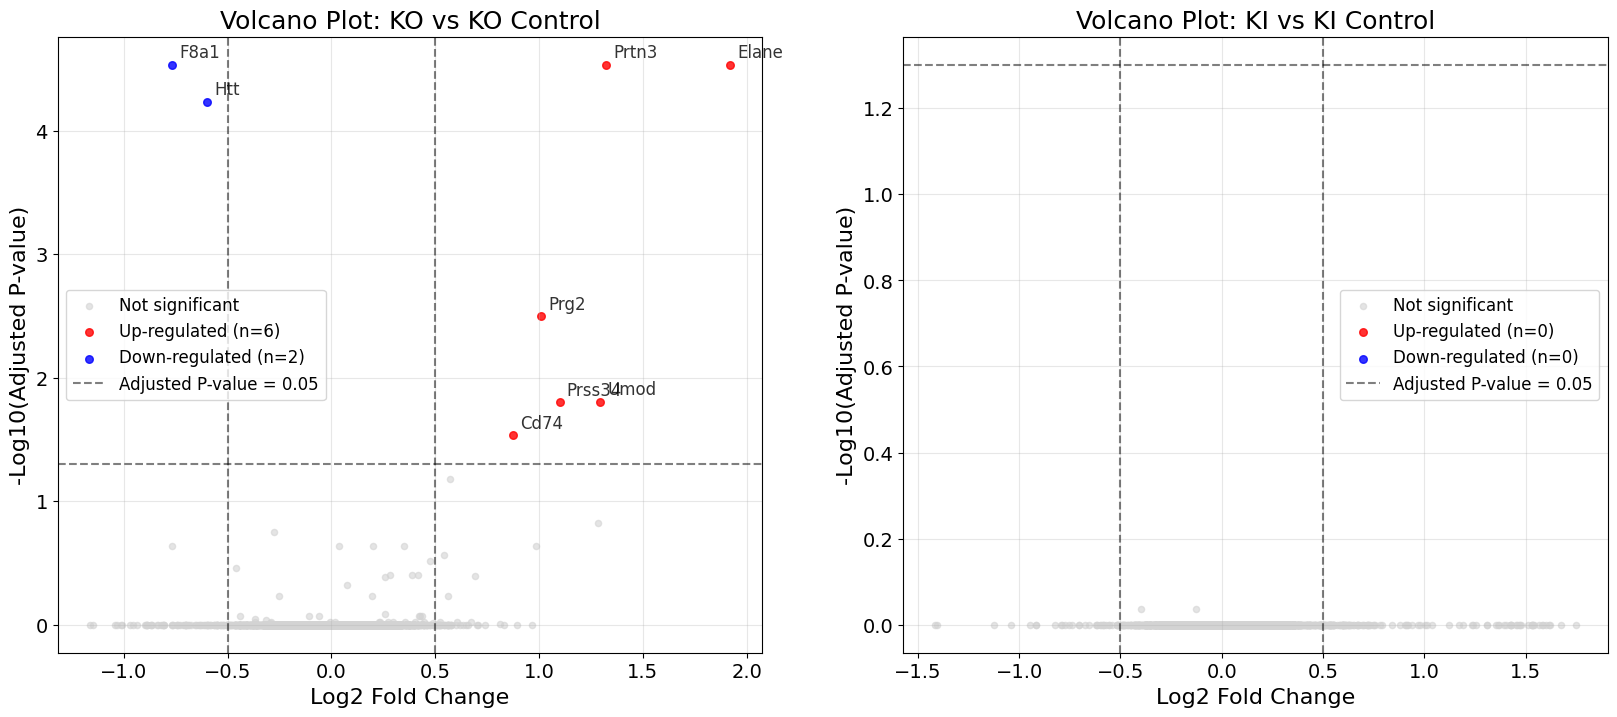

In [49]:
%pip install statsmodels
from scipy import stats
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define the group comparisons
comparisons = [
    ('KO', 'KO Control'),
    ('KI', 'KI Control')
]

def perform_differential_analysis(data, metadata, group1, group2):
    """
    Perform differential analysis between two groups using VSN normalized data
    """
    # Get replicates for each group
    group1_replicates = metadata[metadata['Group'] == group1]['Replicate'].tolist()
    group2_replicates = metadata[metadata['Group'] == group2]['Replicate'].tolist()
    
    # Get corresponding column names
    group1_cols = [col for col in sample_columns if any(rep in col for rep in group1_replicates)]
    group2_cols = [col for col in sample_columns if any(rep in col for rep in group2_replicates)]
    
    print(f"Comparing {group1} (n={len(group1_cols)}) vs {group2} (n={len(group2_cols)})")
    
    results = []
    
    for idx, row in data.iterrows():
        protein = row['Protein']
        description = row['Protein Description']
        gene = row['Protein Gene'] if pd.notna(row['Protein Gene']) else 'Unknown'
        
        # Get values for each group
        group1_values = [row[col] for col in group1_cols if pd.notna(row[col])]
        group2_values = [row[col] for col in group2_cols if pd.notna(row[col])]
        
        if len(group1_values) >= 3 and len(group2_values) >= 3:  # Minimum sample size
            # Calculate means for each group
            mean_group1 = np.mean(group1_values)
            mean_group2 = np.mean(group2_values)
            
            # Calculate fold change (log2)
            log2fc = mean_group1 - mean_group2
            
            # Perform t-test
            t_stat, p_value = stats.ttest_ind(group1_values, group2_values)
            
            results.append({
                'Protein': protein,
                'Description': description,
                'Gene': gene,
                'Log2FC': log2fc,
                'P_value': p_value,
                f'Mean_{group1}': mean_group1,
                f'Mean_{group2}': mean_group2
            })
    
    # Convert to DataFrame
    results_df = pd.DataFrame(results)
    
    # Multiple testing correction (Benjamini-Hochberg)
    rejected, p_adj, alpha_sidak, alpha_bonf = multipletests(
        results_df['P_value'], alpha=0.05, method='fdr_bh'
    )
    
    results_df['P_adj'] = p_adj
    results_df['neg_log10_p'] = -np.log10(results_df['P_value'])
    results_df['neg_log10_p_adj'] = -np.log10(results_df['P_adj'])
    
    # Sort by adjusted p-value
    results_df = results_df.sort_values('P_adj')
    
    return results_df

# Perform differential analysis for both comparisons
all_results = {}

for group1, group2 in comparisons:
    print(f"\n{'='*60}")
    print(f"DIFFERENTIAL ANALYSIS: {group1} vs {group2}")
    print(f"{'='*60}")
    
    results_df = perform_differential_analysis(vsn_protein_data, metadata, group1, group2)
    all_results[f"{group1}_vs_{group2}"] = results_df
    
    # Find significant proteins (BH corrected p-value <= 0.05)
    significant = results_df[results_df['P_adj'] <= 0.05]
    
    print(f"\nTotal proteins tested: {len(results_df)}")
    print(f"Significant proteins (BH p-adj <= 0.05): {len(significant)}")
    
    if len(significant) > 0:
        print(f"\nSignificant proteins:")
        print(significant[['Gene', 'Log2FC', 'P_value', 'P_adj']].head(20))
    else:
        print(f"\nNo proteins with BH corrected p-value <= 0.05")
        print(f"Top 10 most significant proteins:")
        print(results_df[['Gene', 'Log2FC', 'P_value', 'P_adj']].head(10))

# Create volcano plots
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for idx, (comparison_name, results_df) in enumerate(all_results.items()):
    ax = axes[idx]
    
    # Define significance thresholds
    p_adj_threshold = 0.05  # This is for adjusted p-values
    fc_threshold = 0.5  # Log2 fold change threshold
    
    # Classify proteins based on adjusted p-values
    significant = results_df['P_adj'] <= p_adj_threshold
    up_regulated = (results_df['Log2FC'] > fc_threshold) & significant
    down_regulated = (results_df['Log2FC'] < -fc_threshold) & significant
    not_significant = ~significant
    
    # Plot points
    ax.scatter(results_df[not_significant]['Log2FC'], 
              results_df[not_significant]['neg_log10_p'],
              c='lightgray', alpha=0.6, s=20, label='Not significant')
    
    ax.scatter(results_df[up_regulated]['Log2FC'], 
              results_df[up_regulated]['neg_log10_p'],
              c='red', alpha=0.8, s=30, label=f'Up-regulated (n={sum(up_regulated)})')
    
    ax.scatter(results_df[down_regulated]['Log2FC'], 
              results_df[down_regulated]['neg_log10_p'],
              c='blue', alpha=0.8, s=30, label=f'Down-regulated (n={sum(down_regulated)})')
    
    # Use adjusted p-value threshold of 0.05
    y_threshold = -np.log10(0.05)  # This equals 1.3
    
    ax.axhline(y=y_threshold, color='black', linestyle='--', alpha=0.5, 
               label='Adjusted P-value = 0.05')
    ax.axvline(x=fc_threshold, color='black', linestyle='--', alpha=0.5)
    ax.axvline(x=-fc_threshold, color='black', linestyle='--', alpha=0.5)
    
    # Calculate -log10 of adjusted p-values for plotting
    results_df['neg_log10_p_adj'] = -np.log10(results_df['P_adj'])
    
    # Update scatter plots to use adjusted p-values
    ax.clear()  # Clear previous plots
    
    # Re-plot with adjusted p-values
    ax.scatter(results_df[not_significant]['Log2FC'], 
              results_df[not_significant]['neg_log10_p_adj'],
              c='lightgray', alpha=0.6, s=20, label='Not significant')
    
    ax.scatter(results_df[up_regulated]['Log2FC'], 
              results_df[up_regulated]['neg_log10_p_adj'],
              c='red', alpha=0.8, s=30, label=f'Up-regulated (n={sum(up_regulated)})')
    
    ax.scatter(results_df[down_regulated]['Log2FC'], 
              results_df[down_regulated]['neg_log10_p_adj'],
              c='blue', alpha=0.8, s=30, label=f'Down-regulated (n={sum(down_regulated)})')
    
    # Add threshold lines
    ax.axhline(y=y_threshold, color='black', linestyle='--', alpha=0.5, 
               label='Adjusted P-value = 0.05')
    ax.axvline(x=fc_threshold, color='black', linestyle='--', alpha=0.5)
    ax.axvline(x=-fc_threshold, color='black', linestyle='--', alpha=0.5)
    
    # Label significant proteins only
    significant_proteins = results_df[significant]
    for _, protein in significant_proteins.head(10).iterrows():  # Label top 10 significant
        ax.annotate(protein['Gene'], 
                   (protein['Log2FC'], protein['neg_log10_p_adj']),
                   xytext=(5, 5), textcoords='offset points',
                   fontsize=12, alpha=0.8)
    
    # Formatting
    ax.set_xlabel('Log2 Fold Change', fontsize=16)
    ax.set_ylabel('-Log10(Adjusted P-value)', fontsize=16)
    ax.set_title(f'Volcano Plot: {comparison_name.replace("_", " ")}', fontsize=18)
    ax.tick_params(axis='both', which='major', labelsize=14)
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3)



DIFFERENTIAL ANALYSIS: M vs F (Sex comparison)
Available sex annotations: Sex
F    20
M    20
Name: count, dtype: int64
Samples with sex annotation: 40
Comparing M (n=20) vs F (n=20)

Total proteins tested: 9528
Significant proteins (BH p-adj <= 0.05): 117

Significant proteins:
                     Gene    Log2FC       P_value         P_adj
4414                Mup20  2.748608  1.546451e-16  1.473459e-12
7816              Glycam1 -2.435569  3.298921e-15  1.571606e-11
4330                Ovgp1 -1.641288  5.119144e-14  1.625840e-10
9035             Scgb2b17  2.817059  1.947288e-13  4.638440e-10
8861                   C7  1.345885  7.662462e-12  1.223075e-08
3417                Mup21  2.022707  7.701981e-12  1.223075e-08
1947               Crisp1  1.125075  3.014081e-11  4.102595e-08
5355                   C6  1.339532  3.568541e-11  4.250133e-08
7723                Mup14  2.294891  4.694240e-11  4.969635e-08
6094         Mup1 / Mup15  2.268683  5.780073e-11  5.507254e-08
689         Mup

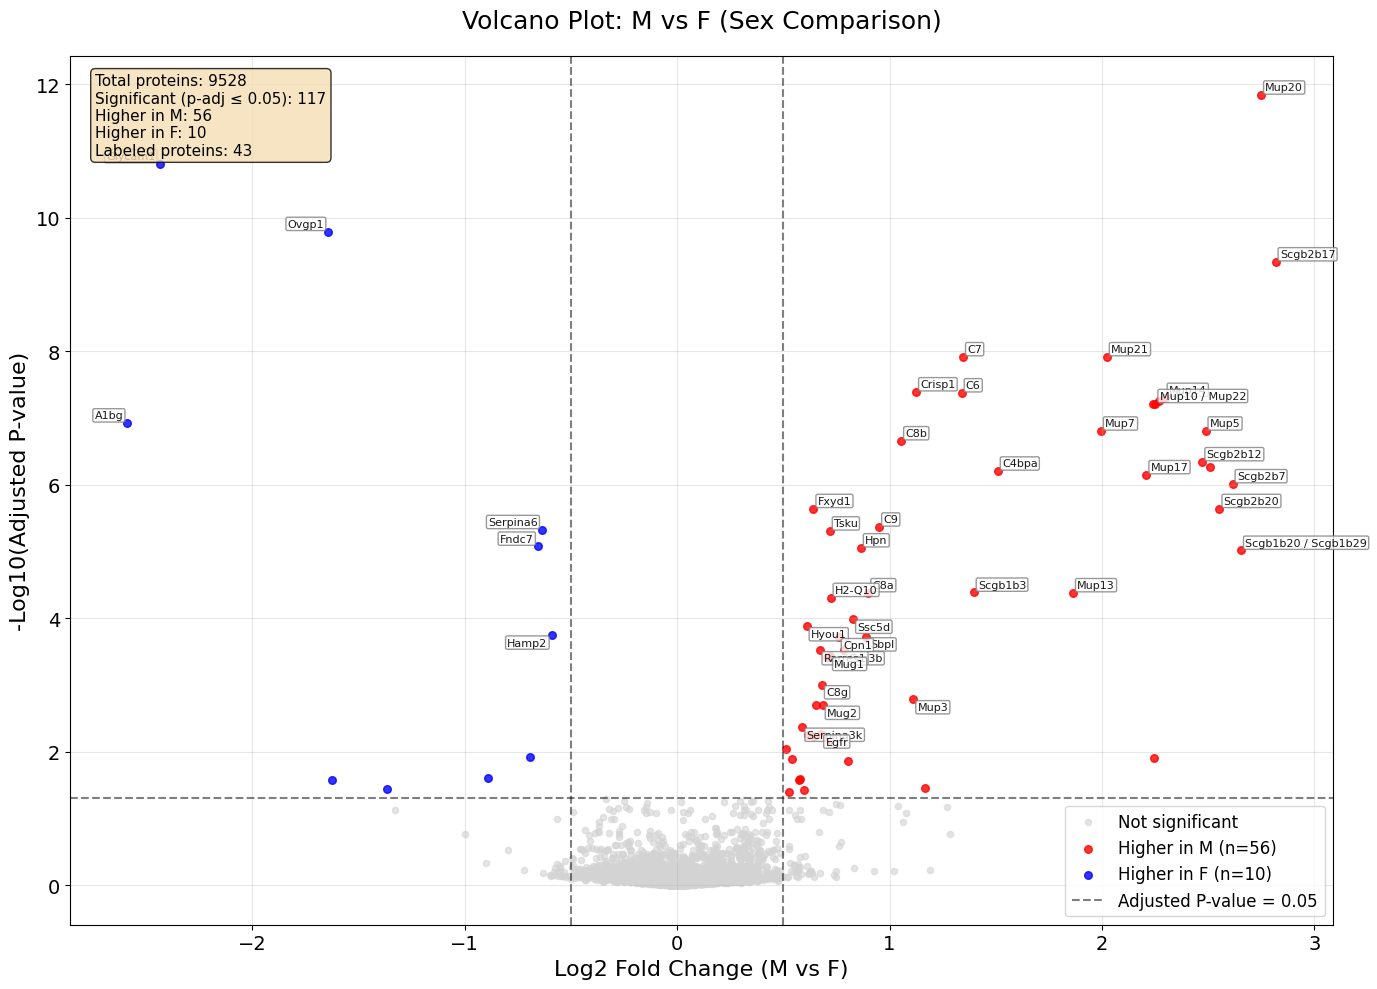

In [50]:
# Perform differential analysis comparing M vs F using VSN normalized data
def perform_sex_differential_analysis(data, metadata, sex1, sex2):
    """
    Perform differential analysis between two sexes using VSN normalized data
    """
    # Get replicates for each sex
    sex1_replicates = metadata[metadata['Sex'] == sex1]['Replicate'].tolist()
    sex2_replicates = metadata[metadata['Sex'] == sex2]['Replicate'].tolist()
    
    # Get corresponding column names
    sex1_cols = [col for col in sample_columns if any(rep in col for rep in sex1_replicates)]
    sex2_cols = [col for col in sample_columns if any(rep in col for rep in sex2_replicates)]
    
    print(f"Comparing {sex1} (n={len(sex1_cols)}) vs {sex2} (n={len(sex2_cols)})")
    
    results = []
    
    for idx, row in data.iterrows():
        protein = row['Protein']
        description = row['Protein Description']
        gene = row['Protein Gene'] if pd.notna(row['Protein Gene']) else 'Unknown'
        
        # Get values for each sex
        sex1_values = [row[col] for col in sex1_cols if pd.notna(row[col])]
        sex2_values = [row[col] for col in sex2_cols if pd.notna(row[col])]
        
        if len(sex1_values) >= 3 and len(sex2_values) >= 3:  # Minimum sample size
            # Calculate means for each sex
            mean_sex1 = np.mean(sex1_values)
            mean_sex2 = np.mean(sex2_values)
            
            # Calculate fold change (log2)
            log2fc = mean_sex1 - mean_sex2
            
            # Perform t-test
            t_stat, p_value = stats.ttest_ind(sex1_values, sex2_values)
            
            results.append({
                'Protein': protein,
                'Description': description,
                'Gene': gene,
                'Log2FC': log2fc,
                'P_value': p_value,
                f'Mean_{sex1}': mean_sex1,
                f'Mean_{sex2}': mean_sex2
            })
    
    # Convert to DataFrame
    results_df = pd.DataFrame(results)
    
    # Multiple testing correction (Benjamini-Hochberg)
    rejected, p_adj, alpha_sidak, alpha_bonf = multipletests(
        results_df['P_value'], alpha=0.05, method='fdr_bh'
    )
    
    results_df['P_adj'] = p_adj
    results_df['neg_log10_p'] = -np.log10(results_df['P_value'])
    results_df['neg_log10_p_adj'] = -np.log10(results_df['P_adj'])
    
    # Sort by adjusted p-value
    results_df = results_df.sort_values('P_adj')
    
    return results_df

# Check if 'Sex' column exists in metadata (note the capital S)
if 'Sex' in metadata.columns:
    print(f"\n{'='*60}")
    print(f"DIFFERENTIAL ANALYSIS: M vs F (Sex comparison)")
    print(f"{'='*60}")
    
    # Check available sex annotations
    print(f"Available sex annotations: {metadata['Sex'].value_counts()}")
    
    # Filter out samples with no sex annotation
    metadata_with_sex = metadata[metadata['Sex'].notna()]
    print(f"Samples with sex annotation: {len(metadata_with_sex)}")
    
    if 'M' in metadata_with_sex['Sex'].values and 'F' in metadata_with_sex['Sex'].values:
        results_sex = perform_sex_differential_analysis(vsn_protein_data, metadata_with_sex, 'M', 'F')
        
        # Find significant proteins (BH corrected p-value <= 0.05)
        significant_sex = results_sex[results_sex['P_adj'] <= 0.05]
        
        print(f"\nTotal proteins tested: {len(results_sex)}")
        print(f"Significant proteins (BH p-adj <= 0.05): {len(significant_sex)}")
        
        if len(significant_sex) > 0:
            print(f"\nSignificant proteins:")
            print(significant_sex[['Gene', 'Log2FC', 'P_value', 'P_adj']].head(20))
        else:
            print(f"\nNo proteins with BH corrected p-value <= 0.05")
            print(f"Top 10 most significant proteins:")
            print(results_sex[['Gene', 'Log2FC', 'P_value', 'P_adj']].head(10))
        
        # Create volcano plot for sex comparison
        plt.figure(figsize=(14, 10))
        
        # Define significance thresholds
        p_adj_threshold = 0.05
        fc_threshold = 0.5
        
        # Classify proteins based on adjusted p-values
        significant = results_sex['P_adj'] <= p_adj_threshold
        up_regulated = (results_sex['Log2FC'] > fc_threshold) & significant
        down_regulated = (results_sex['Log2FC'] < -fc_threshold) & significant
        not_significant = ~significant
        
        # Plot points using adjusted p-values
        plt.scatter(results_sex[not_significant]['Log2FC'], 
                   results_sex[not_significant]['neg_log10_p_adj'],
                   c='lightgray', alpha=0.6, s=20, label='Not significant')
        
        plt.scatter(results_sex[up_regulated]['Log2FC'], 
                   results_sex[up_regulated]['neg_log10_p_adj'],
                   c='red', alpha=0.8, s=30, label=f'Higher in M (n={sum(up_regulated)})')
        
        plt.scatter(results_sex[down_regulated]['Log2FC'], 
                   results_sex[down_regulated]['neg_log10_p_adj'],
                   c='blue', alpha=0.8, s=30, label=f'Higher in F (n={sum(down_regulated)})')
        
        # Add threshold lines
        y_threshold = -np.log10(0.05)
        plt.axhline(y=y_threshold, color='black', linestyle='--', alpha=0.5, 
                   label='Adjusted P-value = 0.05')
        plt.axvline(x=fc_threshold, color='black', linestyle='--', alpha=0.5)
        plt.axvline(x=-fc_threshold, color='black', linestyle='--', alpha=0.5)
        
        # Enhanced labeling strategy - only label proteins that meet BOTH thresholds
        proteins_to_label = []
        
        # Only label proteins that are both statistically significant AND above fold change threshold
        significant_and_fc = results_sex[
            (results_sex['P_adj'] <= p_adj_threshold) & 
            (abs(results_sex['Log2FC']) > fc_threshold)
        ]
        
        if len(significant_and_fc) > 0:
            # Label proteins that meet both criteria (up to a reasonable limit)
            max_labels = min(50, len(significant_and_fc))
            proteins_to_label = significant_and_fc.head(max_labels).index.tolist()
        
        # Create a grid to avoid overlapping labels
        labeled_positions = []
        min_distance = 0.08
        
        for idx in proteins_to_label:
            protein = results_sex.loc[idx]
            x, y = protein['Log2FC'], protein['neg_log10_p_adj']
            
            # Check if this position is too close to existing labels
            too_close = False
            for prev_x, prev_y in labeled_positions:
                if ((x - prev_x)**2 + (y - prev_y)**2)**0.5 < min_distance:
                    too_close = True
                    break
            
            if not too_close:
                # Use smart positioning for labels
                if x > 0:  # Right side
                    ha, offset_x = 'left', 3
                else:  # Left side
                    ha, offset_x = 'right', -3
                
                if y > np.median(significant_and_fc['neg_log10_p_adj']):  # Upper half
                    va, offset_y = 'bottom', 2
                else:  # Lower half
                    va, offset_y = 'top', -2
                
                plt.annotate(protein['Gene'], 
                            (x, y),
                            xytext=(offset_x, offset_y), 
                            textcoords='offset points',
                            fontsize=8,
                            alpha=0.9,
                            ha=ha, va=va,
                            bbox=dict(boxstyle='round,pad=0.15', 
                                     facecolor='white', alpha=0.8, edgecolor='gray'))
                
                labeled_positions.append((x, y))
        
        # Formatting
        plt.xlabel('Log2 Fold Change (M vs F)', fontsize=16)
        plt.ylabel('-Log10(Adjusted P-value)', fontsize=16)
        plt.title('Volcano Plot: M vs F (Sex Comparison)', fontsize=18, pad=20)
        plt.tick_params(axis='both', which='major', labelsize=14)
        
        # Move legend to lower right to avoid covering points
        plt.legend(fontsize=12, loc='lower right')
        plt.grid(True, alpha=0.3)
        
        # Add text box with summary statistics
        textstr = f'Total proteins: {len(results_sex)}\n'
        textstr += f'Significant (p-adj ≤ 0.05): {len(significant_sex)}\n'
        textstr += f'Higher in M: {sum(up_regulated)}\n'
        textstr += f'Higher in F: {sum(down_regulated)}\n'
        textstr += f'Labeled proteins: {len(labeled_positions)}'
        
        props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
        plt.text(0.02, 0.98, textstr, transform=plt.gca().transAxes, fontsize=11,
                verticalalignment='top', bbox=props)
        
        plt.tight_layout()
        plt.show()
        
    else:
        print("Either 'M' or 'F' sex annotations not found in metadata")
else:
    print("'Sex' column not found in metadata")
    print(f"Available columns in metadata: {metadata.columns.tolist()}")
    


[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: C:\Users\macco\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.

DIFFERENTIAL ANALYSIS (MEDIAN SCALED): KO vs KO Control
Comparing KO (n=10) vs KO Control (n=10)

Total proteins tested: 9528
Significant proteins (BH p-adj <= 0.05): 8

Significant proteins:
        Gene    Log2FC       P_value     P_adj
6322   Prtn3  2.293948  1.877498e-08  0.000089
3824    F8a1 -2.032772  1.132766e-08  0.000089
4279     Htt -0.867078  2.998854e-08  0.000095
837    Elane  3.075584  5.035999e-08  0.000120
1911    Prg2  1.460548  1.742451e-06  0.003320
7656  Prss34  1.594869  1.274684e-05  0.017801
5342    Umod  1.881384  1.307794e-05  0.017801
8421    Cd74  1.263248  2.716358e-05  0.032352

DIFFERENTIAL ANALYSIS (MEDIAN SCALED): KI vs KI Control
Comparing KI (n=10) vs KI Control (n=10)

Total proteins tested: 9528
Significant proteins (BH p-adj <= 0.05): 0

No proteins with BH corrected p-value <= 0.05
Top 10 most significant proteins:
                        Gene    Log2FC   P_value     P_adj
0       

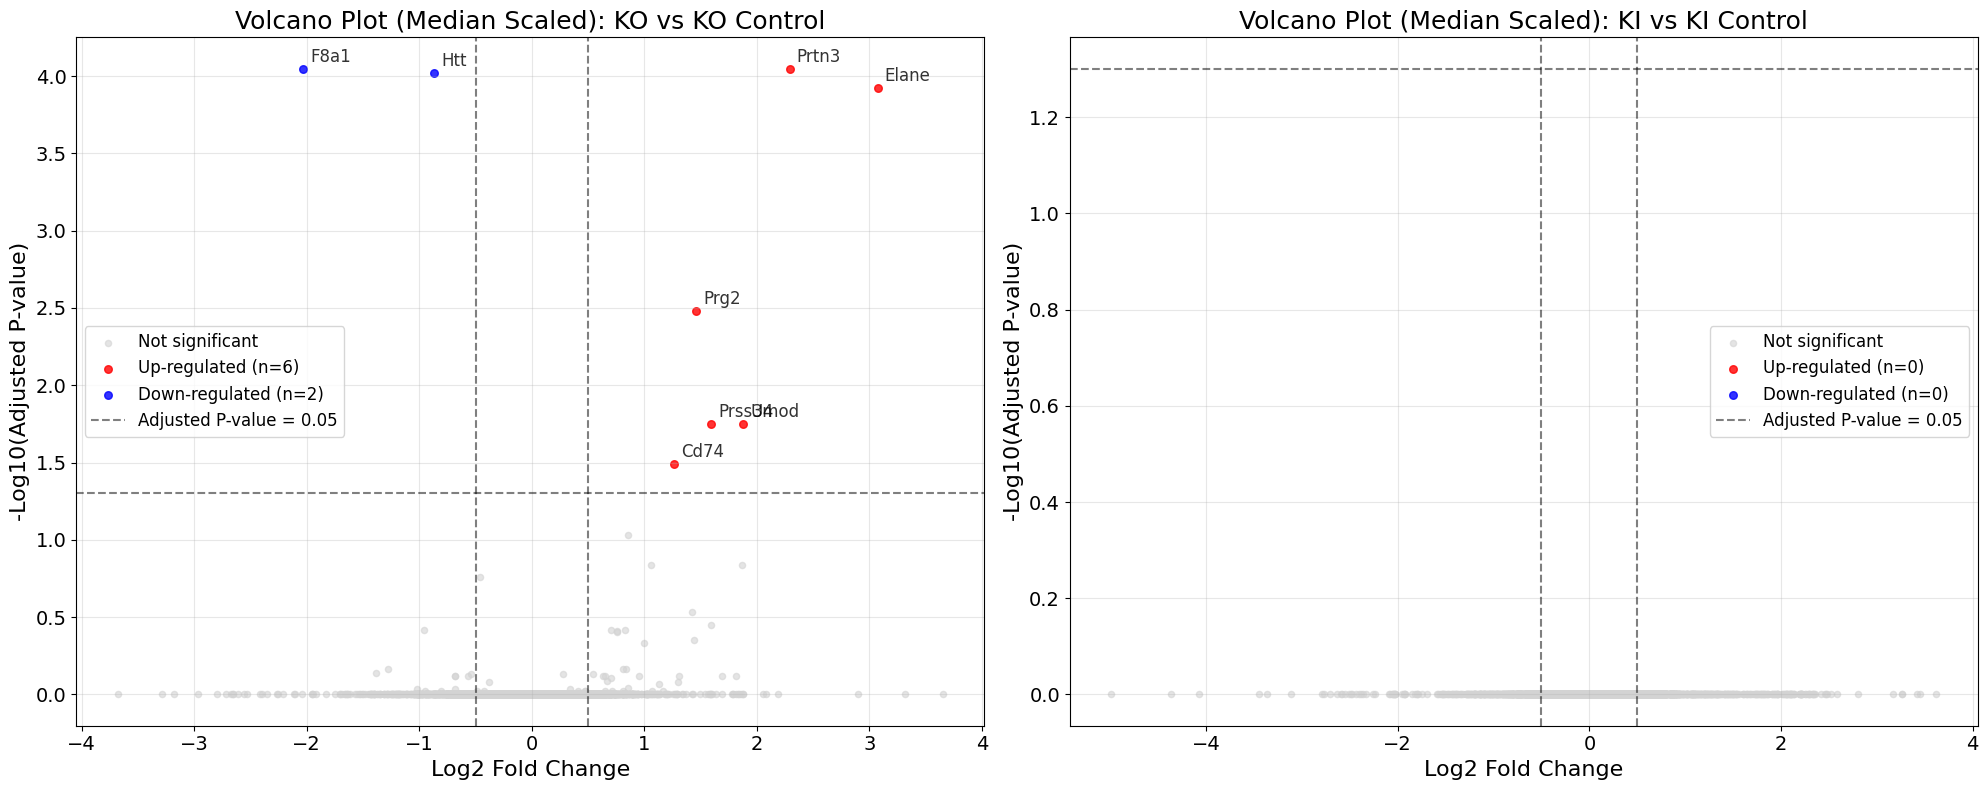

In [51]:
%pip install pandas numpy seaborn matplotlib scipy scikit-learn statsmodels 

from scipy import stats
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

# Define the group comparisons
comparisons = [
    ('KO', 'KO Control'),
    ('KI', 'KI Control')
]

def perform_differential_analysis_median_scaled(data, metadata, group1, group2):
    """
    Perform differential analysis between two groups using median scaled data
    """
    # Get replicates for each group
    group1_replicates = metadata[metadata['Group'] == group1]['Replicate'].tolist()
    group2_replicates = metadata[metadata['Group'] == group2]['Replicate'].tolist()
    
    # Get corresponding column names
    group1_cols = [col for col in sample_columns if any(rep in col for rep in group1_replicates)]
    group2_cols = [col for col in sample_columns if any(rep in col for rep in group2_replicates)]
    
    print(f"Comparing {group1} (n={len(group1_cols)}) vs {group2} (n={len(group2_cols)})")
    
    results = []
    
    for idx, row in data.iterrows():
        protein = row['Protein']
        description = row['Protein Description']
        gene = row['Protein Gene'] if pd.notna(row['Protein Gene']) else 'Unknown'
        
        # Get values for each group
        group1_values = [row[col] for col in group1_cols if pd.notna(row[col])]
        group2_values = [row[col] for col in group2_cols if pd.notna(row[col])]
        
        # Apply log2 transformation (add small constant to avoid log(0))
        group1_log_values = [np.log2(val + 1) for val in group1_values]
        group2_log_values = [np.log2(val + 1) for val in group2_values]
        
        if len(group1_log_values) >= 3 and len(group2_log_values) >= 3:  # Minimum sample size
            # Calculate means for each group
            mean_group1 = np.mean(group1_log_values)
            mean_group2 = np.mean(group2_log_values)
            
            # Calculate fold change (log2)
            log2fc = mean_group1 - mean_group2
            
            # Perform t-test
            t_stat, p_value = stats.ttest_ind(group1_log_values, group2_log_values)
            
            results.append({
                'Protein': protein,
                'Description': description,
                'Gene': gene,
                'Log2FC': log2fc,
                'P_value': p_value,
                f'Mean_{group1}': mean_group1,
                f'Mean_{group2}': mean_group2
            })
    
    # Convert to DataFrame
    results_df = pd.DataFrame(results)
    
    # Multiple testing correction (Benjamini-Hochberg)
    rejected, p_adj, alpha_sidak, alpha_bonf = multipletests(
        results_df['P_value'], alpha=0.05, method='fdr_bh'
    )
    
    results_df['P_adj'] = p_adj
    results_df['neg_log10_p'] = -np.log10(results_df['P_value'])
    results_df['neg_log10_p_adj'] = -np.log10(results_df['P_adj'])
    
    # Sort by adjusted p-value
    results_df = results_df.sort_values('P_adj')
    
    return results_df

# Perform differential analysis for both comparisons using median scaled data
all_results_median_scaled = {}

for group1, group2 in comparisons:
    print(f"\n{'='*60}")
    print(f"DIFFERENTIAL ANALYSIS (MEDIAN SCALED): {group1} vs {group2}")
    print(f"{'='*60}")
    
    results_df = perform_differential_analysis_median_scaled(median_scaled_protein_data, metadata, group1, group2)
    all_results_median_scaled[f"{group1}_vs_{group2}"] = results_df
    
    # Find significant proteins (BH corrected p-value <= 0.05)
    significant = results_df[results_df['P_adj'] <= 0.05]
    
    print(f"\nTotal proteins tested: {len(results_df)}")
    print(f"Significant proteins (BH p-adj <= 0.05): {len(significant)}")
    
    if len(significant) > 0:
        print(f"\nSignificant proteins:")
        print(significant[['Gene', 'Log2FC', 'P_value', 'P_adj']].head(20))
    else:
        print(f"\nNo proteins with BH corrected p-value <= 0.05")
        print(f"Top 10 most significant proteins:")
        print(results_df[['Gene', 'Log2FC', 'P_value', 'P_adj']].head(10))

# Create volcano plots for median scaled data
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for idx, (comparison_name, results_df) in enumerate(all_results_median_scaled.items()):
    ax = axes[idx]
    
    # Define significance thresholds
    p_adj_threshold = 0.05  # This is for adjusted p-values
    fc_threshold = 0.5  # Log2 fold change threshold
    
    # Classify proteins based on adjusted p-values
    significant = results_df['P_adj'] <= p_adj_threshold
    up_regulated = (results_df['Log2FC'] > fc_threshold) & significant
    down_regulated = (results_df['Log2FC'] < -fc_threshold) & significant
    not_significant = ~significant
    
    # Plot points using adjusted p-values
    ax.scatter(results_df[not_significant]['Log2FC'], 
              results_df[not_significant]['neg_log10_p_adj'],
              c='lightgray', alpha=0.6, s=20, label='Not significant')
    
    ax.scatter(results_df[up_regulated]['Log2FC'], 
              results_df[up_regulated]['neg_log10_p_adj'],
              c='red', alpha=0.8, s=30, label=f'Up-regulated (n={sum(up_regulated)})')
    
    ax.scatter(results_df[down_regulated]['Log2FC'], 
              results_df[down_regulated]['neg_log10_p_adj'],
              c='blue', alpha=0.8, s=30, label=f'Down-regulated (n={sum(down_regulated)})')
    
    # Add threshold lines
    y_threshold = -np.log10(0.05)  # This equals 1.3
    ax.axhline(y=y_threshold, color='black', linestyle='--', alpha=0.5, 
               label='Adjusted P-value = 0.05')
    ax.axvline(x=fc_threshold, color='black', linestyle='--', alpha=0.5)
    ax.axvline(x=-fc_threshold, color='black', linestyle='--', alpha=0.5)
    
    # Label significant proteins only
    significant_proteins = results_df[significant]
    for _, protein in significant_proteins.head(10).iterrows():  # Label top 10 significant
        ax.annotate(protein['Gene'], 
                   (protein['Log2FC'], protein['neg_log10_p_adj']),
                   xytext=(5, 5), textcoords='offset points',
                   fontsize=12, alpha=0.8)
    
    # Formatting
    ax.set_xlabel('Log2 Fold Change', fontsize=16)
    ax.set_ylabel('-Log10(Adjusted P-value)', fontsize=16)
    ax.set_title(f'Volcano Plot (Median Scaled): {comparison_name.replace("_", " ")}', fontsize=18)
    ax.tick_params(axis='both', which='major', labelsize=14)
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


DIFFERENTIAL ANALYSIS: KO Control vs KI Control
Comparing KO Control (n=10) vs KI Control (n=10)

Total proteins tested: 9528
Significant proteins (BH p-adj <= 0.05): 289

Significant proteins:
          Gene    Log2FC       P_value     P_adj
3079     Mov10 -1.040569  2.782622e-08  0.000039
6228    Ctla2a  1.984779  2.872918e-08  0.000039
3209     Susd1  1.366642  1.153712e-08  0.000039
3127      Mdh1  2.372697  1.924230e-08  0.000039
9384      Twf2  1.725053  2.484805e-08  0.000039
6659  Serpine2  2.664271  1.406535e-08  0.000039
7493      Npc2 -1.370486  9.700025e-09  0.000039
6410     Thbs1  2.575684  4.633890e-08  0.000055
1302     Fubp1  1.264028  8.448693e-08  0.000083
5223      Glmp -0.880826  8.837387e-08  0.000083
919      Kif3a  2.707955  9.595656e-08  0.000083
4555      Aspg  1.842999  2.005192e-07  0.000159
8889     Ltbp1  2.327079  2.388243e-07  0.000175
7144      Smg8  1.591362  3.704987e-07  0.000235
6142     Ripk1 -0.774911  3.602067e-07  0.000235
4061     Impa2  0.505

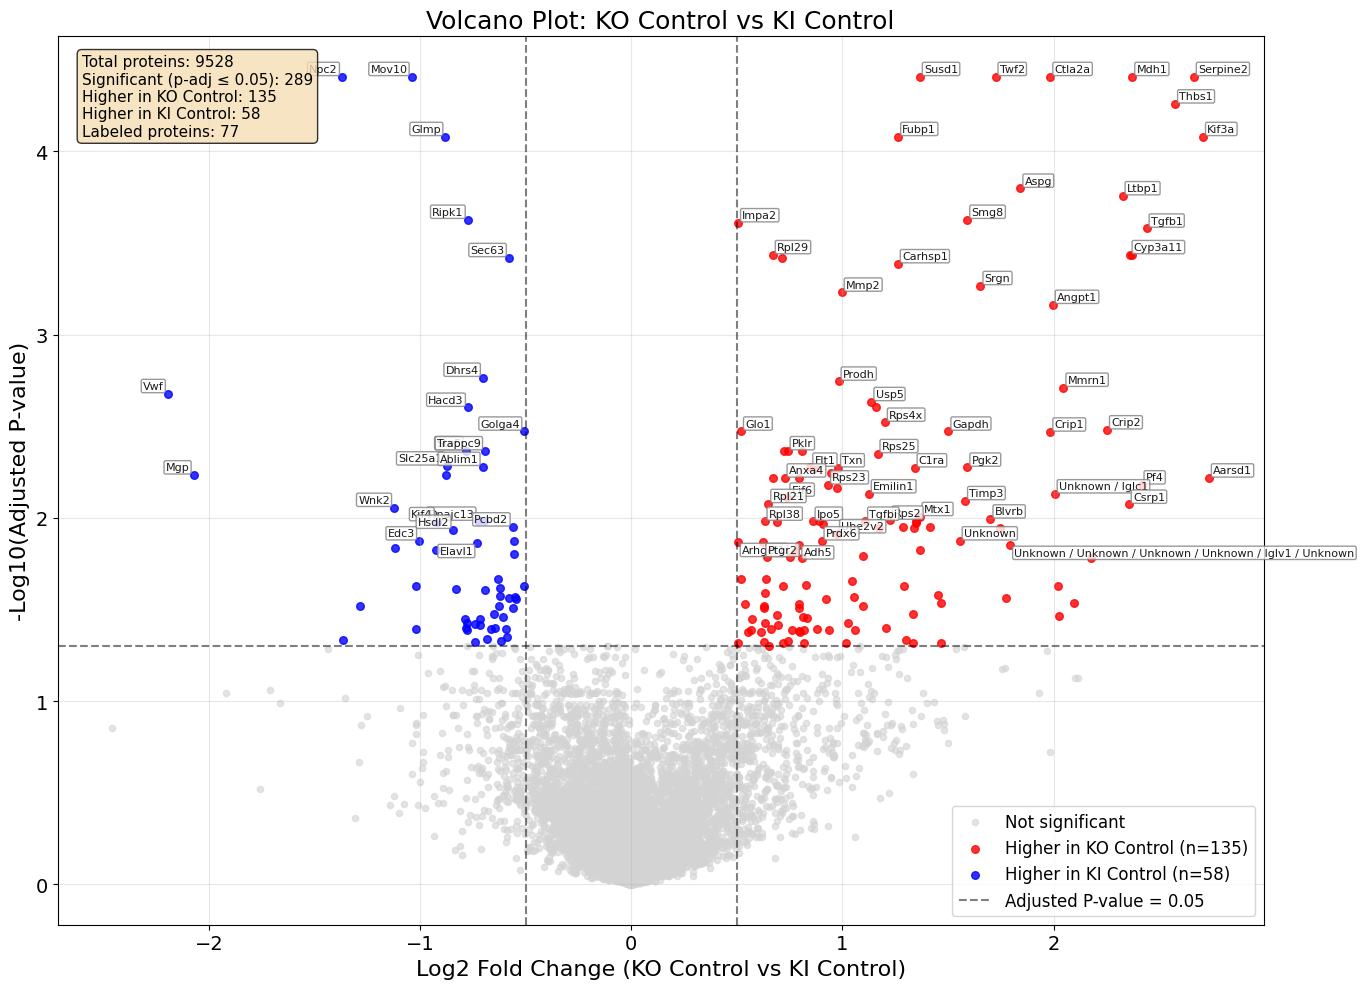

In [55]:
# Perform differential analysis between KO Control and KI Control using VSN normalized data
print(f"\n{'='*60}")
print(f"DIFFERENTIAL ANALYSIS: KO Control vs KI Control")
print(f"{'='*60}")

results_ko_vs_ki = perform_differential_analysis(vsn_protein_data, metadata, 'KO Control', 'KI Control')

# Find significant proteins (BH corrected p-value <= 0.05)
significant_ko_vs_ki = results_ko_vs_ki[results_ko_vs_ki['P_adj'] <= 0.05]

print(f"\nTotal proteins tested: {len(results_ko_vs_ki)}")
print(f"Significant proteins (BH p-adj <= 0.05): {len(significant_ko_vs_ki)}")

if len(significant_ko_vs_ki) > 0:
    print(f"\nSignificant proteins:")
    print(significant_ko_vs_ki[['Gene', 'Log2FC', 'P_value', 'P_adj']].head(20))
else:
    print(f"\nNo proteins with BH corrected p-value <= 0.05")
    print(f"Top 10 most significant proteins:")
    print(results_ko_vs_ki[['Gene', 'Log2FC', 'P_value', 'P_adj']].head(10))

# Create volcano plot for KO Control vs KI Control
plt.figure(figsize=(14, 10))

# Define significance thresholds
p_adj_threshold = 0.05
fc_threshold = 0.5

# Classify proteins based on adjusted p-values
significant = results_ko_vs_ki['P_adj'] <= p_adj_threshold
up_regulated = (results_ko_vs_ki['Log2FC'] > fc_threshold) & significant
down_regulated = (results_ko_vs_ki['Log2FC'] < -fc_threshold) & significant
not_significant = ~significant

# Plot points using adjusted p-values
plt.scatter(results_ko_vs_ki[not_significant]['Log2FC'], 
           results_ko_vs_ki[not_significant]['neg_log10_p_adj'],
           c='lightgray', alpha=0.6, s=20, label='Not significant')

plt.scatter(results_ko_vs_ki[up_regulated]['Log2FC'], 
           results_ko_vs_ki[up_regulated]['neg_log10_p_adj'],
           c='red', alpha=0.8, s=30, label=f'Higher in KO Control (n={sum(up_regulated)})')

plt.scatter(results_ko_vs_ki[down_regulated]['Log2FC'], 
           results_ko_vs_ki[down_regulated]['neg_log10_p_adj'],
           c='blue', alpha=0.8, s=30, label=f'Higher in KI Control (n={sum(down_regulated)})')

# Add threshold lines
y_threshold = -np.log10(0.05)
plt.axhline(y=y_threshold, color='black', linestyle='--', alpha=0.5, 
           label='Adjusted P-value = 0.05')
plt.axvline(x=fc_threshold, color='black', linestyle='--', alpha=0.5)
plt.axvline(x=-fc_threshold, color='black', linestyle='--', alpha=0.5)

# Enhanced labeling strategy - only label proteins that meet BOTH thresholds
proteins_to_label = []

# Only label proteins that are both statistically significant AND above fold change threshold
significant_and_fc = results_ko_vs_ki[
    (results_ko_vs_ki['P_adj'] <= p_adj_threshold) & 
    (abs(results_ko_vs_ki['Log2FC']) > fc_threshold)
]

if len(significant_and_fc) > 0:
    # Label all proteins that meet both criteria (up to a reasonable limit)
    max_labels = min(100, len(significant_and_fc))
    proteins_to_label = significant_and_fc.head(max_labels).index.tolist()

# Create a grid to avoid overlapping labels
labeled_positions = []
min_distance = 0.08

for idx in proteins_to_label:
    protein = results_ko_vs_ki.loc[idx]
    x, y = protein['Log2FC'], protein['neg_log10_p_adj']
    
    # Check if this position is too close to existing labels
    too_close = False
    for prev_x, prev_y in labeled_positions:
        if ((x - prev_x)**2 + (y - prev_y)**2)**0.5 < min_distance:
            too_close = True
            break
    
    if not too_close:
        # Use smart positioning for labels
        if x > 0:  # Right side
            ha, offset_x = 'left', 3
        else:  # Left side
            ha, offset_x = 'right', -3
        
        if y > np.median(significant_and_fc['neg_log10_p_adj']):  # Upper half
            va, offset_y = 'bottom', 2
        else:  # Lower half
            va, offset_y = 'top', -2
        
        plt.annotate(protein['Gene'], 
                    (x, y),
                    xytext=(offset_x, offset_y), 
                    textcoords='offset points',
                    fontsize=8,
                    alpha=0.9,
                    ha=ha, va=va,
                    bbox=dict(boxstyle='round,pad=0.15', 
                             facecolor='white', alpha=0.8, edgecolor='gray'))
        
        labeled_positions.append((x, y))

# Formatting
plt.xlabel('Log2 Fold Change (KO Control vs KI Control)', fontsize=16)
plt.ylabel('-Log10(Adjusted P-value)', fontsize=16)
plt.title('Volcano Plot: KO Control vs KI Control', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)

# Add text box with summary statistics
textstr = f'Total proteins: {len(results_ko_vs_ki)}\n'
textstr += f'Significant (p-adj ≤ 0.05): {len(significant_ko_vs_ki)}\n'
textstr += f'Higher in KO Control: {sum(up_regulated)}\n'
textstr += f'Higher in KI Control: {sum(down_regulated)}\n'
textstr += f'Labeled proteins: {len(labeled_positions)}'

props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
plt.text(0.02, 0.98, textstr, transform=plt.gca().transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

plt.tight_layout()
plt.show()

In [53]:
# Read the report.stats.tsv file
stats_data = pd.read_csv('report.stats.tsv', sep='\t')

# Display the structure of the data
print("Stats data shape:", stats_data.shape)
print("\nColumns:", stats_data.columns.tolist())
print("\nFirst few rows:")
print(stats_data.head())

# Check if we need to merge with metadata to get group information
if 'Group' not in stats_data.columns:
    # Extract replicate name from the data (assuming there's a column with replicate info)
    # We'll need to identify which column contains the replicate information
    print("\nLooking for replicate column...")
    print(stats_data.columns.tolist())
    
    # Assuming the first column or a column named 'Replicate' contains the replicate names
    replicate_col = stats_data.columns[0]  # Adjust this based on actual column name
    
    # Merge with metadata to get group information
    stats_data_merged = stats_data.merge(metadata, left_on=replicate_col, right_on='Replicate', how='left')
else:
    stats_data_merged = stats_data.copy()

print("\nMerged data shape:", stats_data_merged.shape)
print("Sample of merged data:")
print(stats_data_merged.head())

Stats data shape: (48, 17)

Columns: ['File.Name', 'Precursors.Identified', 'Proteins.Identified', 'Total.Quantity', 'MS1.Signal', 'MS2.Signal', 'FWHM.Scans', 'FWHM.RT', 'Median.Mass.Acc.MS1', 'Median.Mass.Acc.MS1.Corrected', 'Median.Mass.Acc.MS2', 'Median.Mass.Acc.MS2.Corrected', 'Normalisation.Instability', 'Median.RT.Prediction.Acc', 'Average.Peptide.Length', 'Average.Peptide.Charge', 'Average.Missed.Tryptic.Cleavages']

First few rows:
                                           File.Name  Precursors.Identified  \
0  Z:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...                 107337   
1  Z:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...                  53115   
2  Z:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...                  30051   
3  Z:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...                  68162   
4  Z:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...                  50045   

   Proteins.Identified  Total.Quantity     MS1.Signal    MS2.Signal  \
0         

Stats data columns: ['File.Name', 'Precursors.Identified', 'Proteins.Identified', 'Total.Quantity', 'MS1.Signal', 'MS2.Signal', 'FWHM.Scans', 'FWHM.RT', 'Median.Mass.Acc.MS1', 'Median.Mass.Acc.MS1.Corrected', 'Median.Mass.Acc.MS2', 'Median.Mass.Acc.MS2.Corrected', 'Normalisation.Instability', 'Median.RT.Prediction.Acc', 'Average.Peptide.Length', 'Average.Peptide.Charge', 'Average.Missed.Tryptic.Cleavages']
Sample file paths:
0    Z:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...
1    Z:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...
2    Z:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...
3    Z:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...
4    Z:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...
Name: File.Name, dtype: object

Extracted replicates:
0           A1-DDY6-001
1           A2-DDZ1-002
2            A3-174-003
3    A4-CarrollPool-004
4           A5-DGA1-005
5           A6-DGA3-006
6            A7-178-007
7            A8-153-008
8      A9-CarlC57BL-009
9           A10-168-010
Na

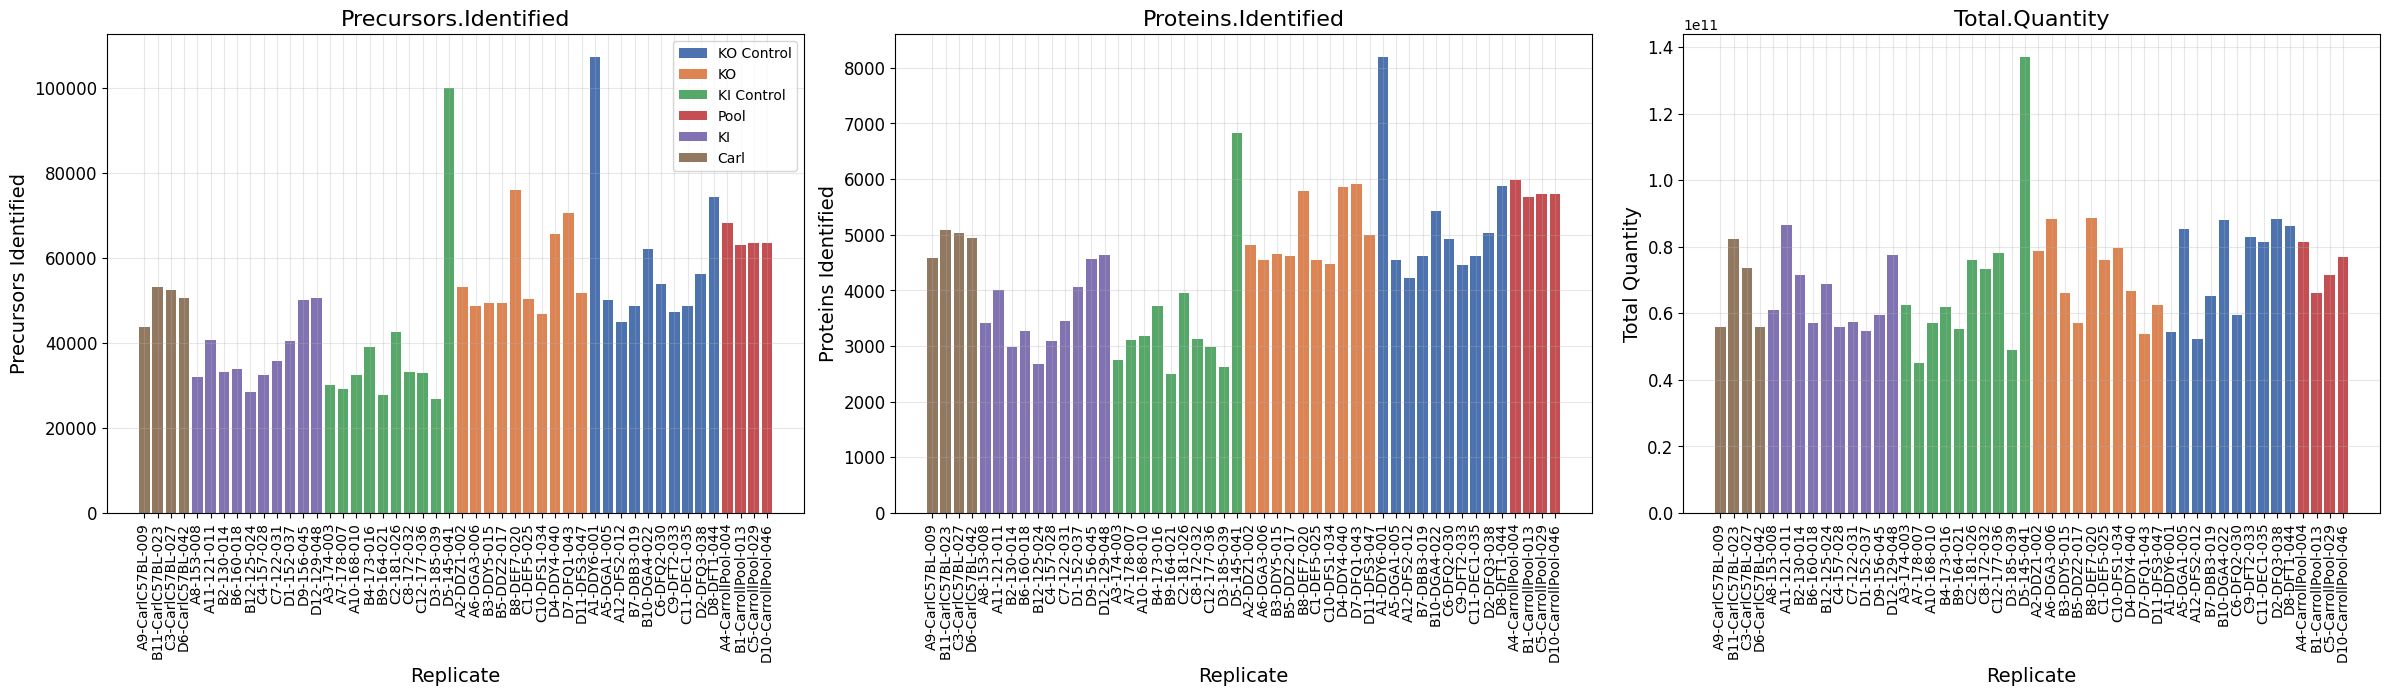

In [54]:
import re

# Read the stats data and extract replicate names from file paths
print("Stats data columns:", stats_data.columns.tolist())
print("Sample file paths:")
print(stats_data.iloc[:5, 0])  # Show first 5 file paths

# Extract replicate names from file paths (after -EV- and before .raw)
def extract_replicate_from_path(file_path):
    """Extract replicate name from file path after -EV- and before .raw"""
    pattern = r'-EV-([A-Z]\d+[^\\/.]*?)\.raw'
    match = re.search(pattern, str(file_path))
    return match.group(1) if match else None

# Assuming the first column contains the file paths
file_path_column = stats_data.columns[0]
stats_data['Replicate'] = stats_data[file_path_column].apply(extract_replicate_from_path)

print("\nExtracted replicates:")
print(stats_data['Replicate'].head(10))

# Merge with metadata
stats_merged = stats_data.merge(metadata, on='Replicate', how='left')

print(f"\nMerged stats data shape: {stats_merged.shape}")
print(f"Successful matches: {stats_merged['Group'].notna().sum()}/{len(stats_merged)}")

# Check available columns for plotting
print("\nAvailable columns in stats_data:")
print([col for col in stats_data.columns if any(keyword in col.lower() for keyword in ['precursor', 'protein', 'quantity', 'signal'])])

# Define metrics to plot (adjust based on actual column names)
metrics = ['Precursors.Identified', 'Proteins.Identified', 'Total.Quantity']
available_metrics = [col for col in metrics if col in stats_data.columns]

if not available_metrics:
    # If exact names don't match, find similar columns
    potential_metrics = []
    for col in stats_data.columns:
        if any(keyword in col.lower() for keyword in ['precursor', 'protein', 'quantity', 'signal']):
            potential_metrics.append(col)
    
    print(f"Found potential metrics: {potential_metrics}")
    available_metrics = potential_metrics[:5]  # Use first 5 found

if available_metrics and len(stats_merged[stats_merged['Group'].notna()]) > 0:
    # Create sample number for ordering
    stats_merged['Sample_Number'] = stats_merged['Replicate'].str.extract(r'(\d+)$')[0].fillna(0).astype(int)
    
    # Create replicate order (same as box plots)
    replicate_order_stats = stats_merged.groupby(['Group', 'Sample_Number', 'Replicate']).size().reset_index()
    replicate_order_stats = replicate_order_stats.sort_values(['Group', 'Sample_Number'])['Replicate'].tolist()
    
    # Use the same color scheme
    group_names = stats_merged['Group'].unique()
    colors = sns.color_palette("deep", n_colors=len(group_names))
    color_map = dict(zip(group_names, colors))
    
    # Create color list for each replicate
    replicate_colors = [color_map[stats_merged[stats_merged['Replicate'] == rep]['Group'].iloc[0]] 
                       for rep in replicate_order_stats if rep in stats_merged['Replicate'].values]
    
    # Create subplots
    n_metrics = min(len(available_metrics), 5)
    fig, axes = plt.subplots(2, 3, figsize=(24, 12))
    axes = axes.flatten()
    
    for idx, metric in enumerate(available_metrics[:5]):
        ax = axes[idx]
        
        # Get data for this metric in the correct order
        metric_data = []
        valid_replicates = []
        valid_colors = []
        
        for rep in replicate_order_stats:
            if rep in stats_merged['Replicate'].values:
                value = stats_merged[stats_merged['Replicate'] == rep][metric].iloc[0]
                metric_data.append(value)
                valid_replicates.append(rep)
                valid_colors.append(color_map[stats_merged[stats_merged['Replicate'] == rep]['Group'].iloc[0]])
        
        # Create bar plot
        bars = ax.bar(range(len(valid_replicates)), metric_data, color=valid_colors)
        
        # Customize the plot
        ax.set_title(f'{metric}', fontsize=16)
        ax.set_ylabel(metric.replace('.', ' '), fontsize=14)
        ax.set_xlabel('Replicate', fontsize=14)
        ax.set_xticks(range(len(valid_replicates)))
        ax.set_xticklabels(valid_replicates, rotation=90, fontsize=10)
        ax.tick_params(axis='y', labelsize=12)
        ax.grid(True, alpha=0.3)
        
        # Add legend only to the first plot
        if idx == 0:
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=color_map[group], label=group) 
                             for group in group_names if pd.notna(group)]
            ax.legend(handles=legend_elements, loc='upper right')
    
    # Remove extra subplots
    for i in range(n_metrics, 6):
        fig.delaxes(axes[i])
    
    plt.tight_layout()
    plt.show()

else:
    print("No suitable metrics found or no successful merges with metadata")
